In [1]:
import numpy as np
import pandas as pd
import io
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib import cm
from matplotlib import colorbar
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, fisher_exact, describe
# from scipy.spatial.distance import jaccard, euclidean, cosine
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.cluster import MeanShift
from scipy.cluster import hierarchy
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

today = date.today()

In [2]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    return fig

In [3]:
f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220817.cleanedgenesmapped.bed', 'r')
mapped_genes = f.readlines()
f.close()

In [4]:
#loading order of each component
f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220815.TFmapped.bed', 'r')
TF_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220815.DHSmapped.bed', 'r')
DHS_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220815.epilogosmapped.bed', 'r')
epilogos_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

In [5]:
#descriptors for each factor
pickle_in = open('/home/ctrader/region_similarity/data/tf_motif_descriptor_dict_CT20220627.pickle', 'rb')
TFfact2descr = pickle.load(pickle_in)

pickle_in = open('/home/ctrader/region_similarity/data/DHS_descriptor_dict_CT20220729.pickle', 'rb')
DHSfact2descr = pickle.load(pickle_in)

pickle_in = open('/home/ctrader/region_similarity/data/epilogos_descriptor_dict_CT20220627.pickle', 'rb')
epilogosfact2descr = pickle.load(pickle_in)

In [6]:
DHS_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.DHScosine.hdf5'
TF_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.TFcosine.hdf5'
epilogos_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.epilogoscosine.hdf5'
coex_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.coexpression_human_transferred_maxSTRINGsimilarity.hdf5'
# coextrans_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.coexpression_transferredSTRINGsimilarity.hdf5'
cooccur_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.cooccurenceSTRINGsimilarity.hdf5'
database_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.database_human_transferred_maxSTRINGsimilarity.hdf5'
exper_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.experiments_human_transferred_maxSTRINGsimilarity.hdf5'
# expertrans_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.experiments_transferredSTRINGsimilarity.hdf5'
fusion_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.fusionSTRINGsimilarity.hdf5'
homology_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.homologySTRINGsimilarity.hdf5'
neigh_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.neighborhood_human_transferred_maxSTRINGsimilarity.hdf5'
textmin_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.textmining_human_transferred_maxSTRINGsimilarity.hdf5'
# textmintrans_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.textmining_transferredSTRINGsimilarity.hdf5'

DHS_ooe_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.DHSoee.hdf5'
TF_ooe_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.TFoee.hdf5'
epilogos_ooe_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.epilogosoee.hdf5'

DHS_mapped_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.DHSmapped.bed'
TF_mapped_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.TFmapped.bed'
epilogos_mapped_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220815.epilogosmapped.bed'

regions_path = '/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220815.sorted.c1t3.bed'
gz_file_path = '/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220815.sorted.c1t3.rownum4.bed.gz'

geneID2name_path = '/home/ctrader/region_similarity/data/gene_proteinID2genename_dict_CT20220712.pickle'

In [7]:
DHS_ooe_hdf5 = h5py.File('/home/ctrader/region_similarity/data/regions_25kb_CT20220815.DHSoee.hdf5', 'r')
DHS_ooe = DHS_ooe_hdf5['ooe_arr'][:]
DHS_ooe_hdf5.close()
TF_ooe_hdf5 = h5py.File('/home/ctrader/region_similarity/data/regions_25kb_CT20220815.TFoee.hdf5', 'r')
TF_ooe = TF_ooe_hdf5['ooe_arr'][:]
TF_ooe_hdf5.close()
epilogos_ooe_hdf5 = h5py.File('/home/ctrader/region_similarity/data/regions_25kb_CT20220815.epilogosoee.hdf5', 'r')
epilogos_ooe = epilogos_ooe_hdf5['ooe_arr'][:]
epilogos_ooe_hdf5.close()

In [8]:
pickle_in = open('/home/ctrader/region_similarity/data/gene_proteinID2genename_dict_CT20220712.pickle', 'rb')
geneID2name = pickle.load(pickle_in)

In [9]:
def combine_scores_multiple(DHS_count_scaled_vals, DHS_count_similar_regions, TF_count_scaled_vals, TF_count_similar_regions, epilogos_score_scaled_vals,
                            epilogos_score_similar_regions, coex_scaled_vals, coex_similar_regions, cooccur_scaled_vals, cooccur_similar_regions,
                            database_scaled_vals, database_similar_regions, exper_scaled_vals, exper_similar_regions,fusion_scaled_vals, fusion_similar_regions,
                            homology_scaled_vals, homology_similar_regions, neigh_scaled_vals, neigh_similar_regions, textmin_scaled_vals, textmin_similar_regions):
    #max ind for combined score array
    max_ind = np.max([DHS_count_similar_regions, TF_count_similar_regions, epilogos_score_similar_regions, coex_similar_regions,
                     cooccur_similar_regions, database_similar_regions, exper_similar_regions, fusion_similar_regions, homology_similar_regions,
                     neigh_similar_regions, textmin_similar_regions])

    #DHS scores
    DHS_arr = create_arr_multiple(DHS_count_similar_regions, DHS_count_scaled_vals, max_ind)
    #epilogos scores
    epilogos_arr = create_arr_multiple(epilogos_score_similar_regions, epilogos_score_scaled_vals, max_ind)
    #TF motif scores
    TF_arr = create_arr_multiple(TF_count_similar_regions, TF_count_scaled_vals, max_ind)
    #coexpression scores
    coex_arr = create_arr_multiple(coex_similar_regions, coex_scaled_vals, max_ind)
    #cooccurrence scores
    cooccur_arr = create_arr_multiple(cooccur_similar_regions, cooccur_scaled_vals, max_ind)
    #database scores
    database_arr = create_arr_multiple(database_similar_regions, database_scaled_vals, max_ind)
    #experiment scores
    exper_arr = create_arr_multiple(exper_similar_regions, exper_scaled_vals, max_ind)
    #fusion scores
    fusion_arr = create_arr_multiple(fusion_similar_regions, fusion_scaled_vals, max_ind)
    #homology scores
    homology_arr = create_arr_multiple(homology_similar_regions, homology_scaled_vals, max_ind)
    #neighborhood scores
    neigh_arr = create_arr_multiple(neigh_similar_regions, neigh_scaled_vals, max_ind)
    #text mining scores
    textmin_arr = create_arr_multiple(textmin_similar_regions, textmin_scaled_vals, max_ind)

    #scoring all metrics
    score_arr = 1 - ((1 - epilogos_arr) * (1 - DHS_arr) * (1 - TF_arr) * (1 - coex_arr) * (1 - cooccur_arr) * (1 - database_arr) * (1 - exper_arr) *
                     (1 - fusion_arr) * (1 - homology_arr) * (1 - neigh_arr) * (1 - textmin_arr))

    #labeling most contributing metrics for each region
    contributing_cosine_arr = np.argmax(np.array((DHS_arr, TF_arr, epilogos_arr, coex_arr, cooccur_arr, database_arr, exper_arr, fusion_arr,
                                                  homology_arr, neigh_arr, textmin_arr)), axis=0)

    return (score_arr, contributing_cosine_arr, max_ind, DHS_arr, TF_arr, epilogos_arr, coex_arr, 
            cooccur_arr, database_arr, exper_arr, fusion_arr, homology_arr, neigh_arr, textmin_arr)

def region_return_multiple(score_arr, contributing_cosine_arr, roi, regions_path, DHS_ooe_path, TF_ooe_path, epilogos_ooe_path, DHS_mapped_path, TF_mapped_path,
                           epilogos_mapped_path, coex_genes, cooccur_genes, database_genes, exper_genes, fusion_genes, homology_genes, neigh_genes,
                           textmin_genes, geneID2name_path):

    #top 100 region inds and scores
    rec_inds = np.argsort(-score_arr)[:, :100]
    top_region_inds = np.hstack((roi.reshape(-1, 1), rec_inds))
    # top_region_scores = np.append(1, score_arr[rec_inds])

    return top_region_inds

def roi_url(roi, top_regions):
    today = date.today()
    roi_url_name = 'region_comparison_recommended_regions_roi_'+str(roi)+'_scale_25kb_CT' + today.strftime("%Y%m%d") + '.bed'
    bed_path_name = os.path.join('/home/ctrader/public_html/', roi_url_name)
    np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
    link_path1 = 'https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roi_url_name
    link_path2 = 'https://index.altius.org:1234/?application=viewer&mode=pd&chrLeft=chr11&chrRight=chr11&start=47329800&stop=47356800&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roi_url_name
    return link_path1, link_path2, bed_path_name

def load_hdf5_files_multiple(hdf5_path, roi):
    #take in a file path and load scaled scores and similar regions
    hdf5_file = h5py.File(hdf5_path, 'r')
    scaled_vals = hdf5_file['top_1000_scaled_vals'][roi]
    similar_regions = hdf5_file['top_1000_similar_regions'][roi]
    hdf5_file.close()
    return scaled_vals, similar_regions

def load_hdf5_genes_multiple(hdf5_path, roi, similar_regions, max_ind):
    #load in tracking genes
    hdf5_file = h5py.File(hdf5_path, 'r')
    ori_genes = np.char.decode(hdf5_file['top_1000_original_genes'][roi], 'utf-8')
    dest_genes = np.char.decode(hdf5_file['top_1000_destination_genes'][roi], 'utf-8')
    #establishing gene arrays
    ori_arr = np.where(np.zeros((len(similar_regions), max_ind + 1))==0, None, None)
    dest_arr = np.where(np.zeros((len(similar_regions), max_ind + 1))==0, None, None)

    #filling gene arrays
    #find the values to change
    cols = similar_regions
    rows = np.array([np.arange(len(similar_regions))]*len(similar_regions[0])).T

    #set values
    ori_arr[rows, cols] = ori_genes
    dest_arr[rows, cols] = dest_genes
    return np.array([ori_arr, dest_arr])

def create_arr_multiple(similar_regions, scaled_vals, max_ind):
    #empty array
    arr = np.zeros((len(similar_regions), max_ind + 1))
    
    #find the values to change
    cols = similar_regions
    rows = np.array([np.arange(len(similar_regions))]*len(similar_regions[0])).T
    
    #set values
    arr[rows, cols] = scaled_vals
    return arr

In [10]:
roi = np.arange(6434, 6434+2)

In [11]:
genomic_location = 'chr1:198636000-198661000'
gz_tb = tabix.open(gz_file_path)
# roi = int(list(gz_tb.querys(genomic_location))[0][3])
roi = np.array(list(gz_tb.querys(genomic_location)))[:, 3].astype(int)

In [12]:
roi

array([6434, 6435])

In [13]:
print('roi = ' + str(roi), flush=True)
t = time.time()

###Load rank and ind arrays
#DHS counts
DHS_count_scaled_vals, DHS_count_similar_regions = load_hdf5_files_multiple(DHS_hdf5_path, roi)
#TF motif counts
TF_count_scaled_vals, TF_count_similar_regions = load_hdf5_files_multiple(TF_hdf5_path, roi)
#epilogos score sum and max
epilogos_score_scaled_vals, epilogos_score_similar_regions = load_hdf5_files_multiple(epilogos_hdf5_path, roi)
#coexpression STRING scores
coex_scaled_vals, coex_similar_regions = load_hdf5_files_multiple(coex_hdf5_path, roi)
#cooccurence STRING scores
cooccur_scaled_vals, cooccur_similar_regions = load_hdf5_files_multiple(cooccur_hdf5_path, roi)
#database STRING scores
database_scaled_vals, database_similar_regions = load_hdf5_files_multiple(database_hdf5_path, roi)
#experiments STRING scores
exper_scaled_vals, exper_similar_regions = load_hdf5_files_multiple(exper_hdf5_path, roi)
#fusion STRING scores
fusion_scaled_vals, fusion_similar_regions = load_hdf5_files_multiple(fusion_hdf5_path, roi)
#homology STRING scores
homology_scaled_vals, homology_similar_regions = load_hdf5_files_multiple(homology_hdf5_path, roi)
#neighborhood STRING scores
neigh_scaled_vals, neigh_similar_regions = load_hdf5_files_multiple(neigh_hdf5_path, roi)
#textmining STRING scores
textmin_scaled_vals, textmin_similar_regions = load_hdf5_files_multiple(textmin_hdf5_path, roi)

###Combine scores 
(score_arr, contributing_cosine_arr, 
 max_ind, DHS_arr, TF_arr, epilogos_arr, 
 coex_arr, cooccur_arr, database_arr, 
 exper_arr, fusion_arr, homology_arr, 
 neigh_arr, textmin_arr) = combine_scores_multiple(DHS_count_scaled_vals, DHS_count_similar_regions, 
                                                   TF_count_scaled_vals, TF_count_similar_regions, 
                                                   epilogos_score_scaled_vals, epilogos_score_similar_regions, 
                                                   coex_scaled_vals, coex_similar_regions, 
                                                   cooccur_scaled_vals, cooccur_similar_regions,
                                                   database_scaled_vals, database_similar_regions, 
                                                   exper_scaled_vals, exper_similar_regions, 
                                                   fusion_scaled_vals, fusion_similar_regions,
                                                   homology_scaled_vals, homology_similar_regions, 
                                                   neigh_scaled_vals, neigh_similar_regions, 
                                                   textmin_scaled_vals, textmin_similar_regions)

#load in gene names for STRING scores
coex_genes = load_hdf5_genes_multiple(coex_hdf5_path, roi, coex_similar_regions, max_ind)
cooccur_genes = load_hdf5_genes_multiple(cooccur_hdf5_path, roi, cooccur_similar_regions, max_ind)
database_genes = load_hdf5_genes_multiple(database_hdf5_path, roi, database_similar_regions, max_ind)
exper_genes = load_hdf5_genes_multiple(exper_hdf5_path, roi, exper_similar_regions, max_ind)
fusion_genes = load_hdf5_genes_multiple(fusion_hdf5_path, roi, fusion_similar_regions, max_ind)
homology_genes = load_hdf5_genes_multiple(homology_hdf5_path, roi, homology_similar_regions, max_ind)
neigh_genes = load_hdf5_genes_multiple(neigh_hdf5_path, roi, neigh_similar_regions, max_ind)
textmin_genes = load_hdf5_genes_multiple(textmin_hdf5_path, roi, textmin_similar_regions, max_ind)

###Return regions
top_region_inds = region_return_multiple(score_arr, contributing_cosine_arr, roi, regions_path, DHS_ooe_path, TF_ooe_path, epilogos_ooe_path, DHS_mapped_path, TF_mapped_path,
                                         epilogos_mapped_path, coex_genes, cooccur_genes, database_genes, exper_genes, fusion_genes, homology_genes, neigh_genes,
                                         textmin_genes, geneID2name_path)

print(time.time()-t, flush=True)

roi = [6434 6435]
2.3823883533477783


In [13]:
#find the values
cols = top_region_inds[:, 1:]
rows = np.array([np.arange(len(top_region_inds[:, 1:]))]*len(top_region_inds[:, 1:][0])).T

DHS_arr_top_100 = DHS_arr[rows, cols]
TF_arr_top_100 = TF_arr[rows, cols]
epilogos_arr_top_100 = epilogos_arr[rows, cols]

# all_metrics_arr = np.array((DHS_arr, TF_arr, epilogos_arr, coex_arr, cooccur_arr, 
#                              database_arr, exper_arr, fusion_arr, homology_arr, 
#                              neigh_arr, textmin_arr))
# string_arr_top_100 = all_metrics_arr[3:, rows, cols]
string_arr_top_100 = np.array((coex_arr, cooccur_arr, database_arr, exper_arr, fusion_arr, homology_arr, 
                               neigh_arr, textmin_arr))[:, rows, cols]

#     string_comp_order = ['Co-expressed with', 'Co-occurs within Species with', 'Co-annotated with', 
#                          'Interacts in vitro with', 'Fused in Other Species with', 'Has Common Ancestory with', 
#                          'is Nearby', 'Co-occurs in Literature with']
string_comp_order = ['Co-expression', 'Co-occurence', 'Co-annotation', 
                     'Interactions in vitro', 'Fusion in Other Species', 'Common Ancestory', 
                     'being Nearby', 'Co-citation']
colors = np.array(['#a6cee3', '#1f78b4', '#b2df8a', '#33a02c', '#fb9a99', '#e31a1c', '#fdbf6f', '#ff7f00', 
                   '#cab2d6', '#6a3d9a', '#ffff99'])

#roi comps
DHS_roi_rank = rankdata(-DHS_ooe[top_region_inds[:, 0]], axis=1)
TF_roi_rank = rankdata(-TF_ooe[top_region_inds[:, 0]], axis=1)
epilogos_roi_mean_rank = rankdata(-epilogos_ooe[top_region_inds[:, 0]][:, :18], axis=1)
epilogos_roi_max_rank = rankdata(-epilogos_ooe[top_region_inds[:, 0]][:, 18:], axis=1)

In [14]:
#find genomic locations
f = open(regions_path, 'r')
regions = f.readlines()
regions_for_sentences = []
for ind in roi:
    regions_for_sentences.append(regions[ind].strip().split())
f.close()

In [13]:
os.chdir('./pipeline_analysis_scripts')

In [14]:
####can delete



from region_comparison_pipeline_analysis_functions_multiple_CT20220818 import combine_scores_multiple, region_return_multiple, load_hdf5_files_multiple, load_hdf5_genes_multiple, create_arr_multiple, combine_scores_multiple_total
TFfact2descr_path = '/home/ctrader/region_similarity/data/tf_motif_descriptor_dict_CT20220627.pickle'
DHSfact2descr_path = '/home/ctrader/region_similarity/data/DHS_descriptor_dict_CT20220729.pickle'
epifact2descr_path = '/home/ctrader/region_similarity/data/epilogos_descriptor_dict_CT20220627.pickle'
out_bed_path = 'delete.bed'

#can delete
#load ooe files
DHS_ooe_hdf5 = h5py.File(DHS_ooe_path, 'r')
DHS_ooe = DHS_ooe_hdf5['ooe_arr'][:]
DHS_ooe_hdf5.close()
TF_ooe_hdf5 = h5py.File(TF_ooe_path, 'r')
TF_ooe = TF_ooe_hdf5['ooe_arr'][:]
TF_ooe_hdf5.close()
epilogos_ooe_hdf5 = h5py.File(epilogos_ooe_path, 'r')
epilogos_ooe = epilogos_ooe_hdf5['ooe_arr'][:]
epilogos_ooe_hdf5.close()

#descriptors for each factor
pickle_in = open(TFfact2descr_path, 'rb')
TFfact2descr = pickle.load(pickle_in)
pickle_in = open(DHSfact2descr_path, 'rb')
DHSfact2descr = pickle.load(pickle_in)
pickle_in = open(epifact2descr_path, 'rb')
epilogosfact2descr = pickle.load(pickle_in)

#loading order of each component
f = open(TF_mapped_path, 'r')
TF_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()
f = open(DHS_mapped_path, 'r')
DHS_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()
f = open(epilogos_mapped_path, 'r')
epilogos_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

pickle_in = open(geneID2name_path, 'rb')
geneID2name = pickle.load(pickle_in)

#retrieve score arrays for regions of interest
roi, top_region_inds, all_metrics_arr_top_100, all_arr_ori, all_arr_dest = combine_scores_multiple_total(gz_file_path, genomic_location, DHS_hdf5_path, TF_hdf5_path, epilogos_hdf5_path,
                                                                                                         coex_hdf5_path, cooccur_hdf5_path, database_hdf5_path, exper_hdf5_path, fusion_hdf5_path,
                                                                                                         homology_hdf5_path, neigh_hdf5_path, textmin_hdf5_path, regions_path, DHS_ooe_path,
                                                                                                         TF_ooe_path, epilogos_ooe_path, DHS_mapped_path, TF_mapped_path, epilogos_mapped_path,
                                                                                                         geneID2name_path, out_bed_path)
#unpack
score_arr_top_100 = all_metrics_arr_top_100[0]
DHS_arr_top_100 = all_metrics_arr_top_100[1]
TF_arr_top_100 = all_metrics_arr_top_100[2]
epilogos_arr_top_100 = all_metrics_arr_top_100[3]
string_arr_top_100 = all_metrics_arr_top_100[4:]


#roi comps
DHS_roi_rank = rankdata(-DHS_ooe[top_region_inds[:, 0]], axis=1)
TF_roi_rank = rankdata(-TF_ooe[top_region_inds[:, 0]], axis=1)
epilogos_roi_mean_rank = rankdata(-epilogos_ooe[top_region_inds[:, 0]][:, :18], axis=1)
epilogos_roi_max_rank = rankdata(-epilogos_ooe[top_region_inds[:, 0]][:, 18:], axis=1)


#bar plots only 
all_metrics_arr_top_100 = all_metrics_arr_top_100[1:]

roi = [6434 6435]
Time to load data and find similar regions = 2.385699510574341


In [84]:
string_comp_order = ['Co-expression', 'Co-occurence', 'Co-annotation', 
                     'Interactions in vitro', 'Fusion in Other Species', 'Common Ancestory', 
                     'being Nearby', 'Co-citation']
for r in range(len(roi)):
    sentence = make_sentence(top_region_inds[r], DHS_arr_top_100[r], TF_arr_top_100[r], epilogos_arr_top_100[r], string_arr_top_100[:, r], DHS_roi_rank[r], TF_roi_rank[r],
                             epilogos_roi_mean_rank[r], epilogos_roi_max_rank[r], DHS_component_order, TF_component_order, epilogos_component_order, string_comp_order,
                             DHSfact2descr, TFfact2descr, epilogosfact2descr, all_arr_ori[:, r], all_arr_dest[:, r], DHS_ooe, TF_ooe, epilogos_ooe, geneID2name)
    print(roi[r], r)
    print(sentence, flush=True)

6434 0
Gene PTPRC (with Co-expression in 96% of regions).
6435 1
Gene PTPRC (with Co-expression in 99% of regions).


In [80]:
def make_sentence(top_region_inds, DHS_arr_top_100, TF_arr_top_100, epilogos_arr_top_100, string_arr_top_100, DHS_roi_rank, TF_roi_rank,
                  epilogos_roi_mean_rank, epilogos_roi_max_rank, DHS_component_order, TF_component_order, epilogos_component_order, string_comp_order,
                  DHSfact2descr, TFfact2descr, epilogosfact2descr, all_arr_ori, all_arr_dest, DHS_ooe, TF_ooe, epilogos_ooe, geneID2name):

    topfactor2region = {}
    #find top comps for each metric/recommended region
    #DHS scores
    for i in range(len(DHS_arr_top_100)):
        if DHS_arr_top_100[i] > 0:
            DHS_i_rank = rankdata(-DHS_ooe[top_region_inds[i+1]])
            top_comp = np.argsort((DHS_roi_rank+DHS_i_rank)/2)[0]
            f = 'DHS ' + DHSfact2descr[DHS_component_order[top_comp]]
            if f not in topfactor2region:
                topfactor2region[f] = np.array([i])
            else:
                topfactor2region[f] = np.append(topfactor2region[f], [i])

    #TF motif scores
    for i in range(len(TF_arr_top_100)):
        if TF_arr_top_100[i] > 0:
            TF_i_rank = rankdata(-TF_ooe[top_region_inds[i+1]])
            top_comp = np.argsort((TF_roi_rank+TF_i_rank)/2)[0]
            f = 'TF ' + TF_component_order[top_comp] + ': ' + TFfact2descr[TF_component_order[top_comp]]
            if f not in topfactor2region:
                topfactor2region[f] = np.array([i])
            else:
                topfactor2region[f] = np.append(topfactor2region[f], [i])

    #chromatin state scores
    for i in range(len(epilogos_arr_top_100)):
        if epilogos_arr_top_100[i] > 0:
            epilogos_i_mean_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][:18])
            epilogos_i_max_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][18:])
            top_mean_comp = np.argsort((epilogos_roi_mean_rank + epilogos_i_mean_rank)/2)[0]
            top_max_comp = np.argsort((epilogos_roi_max_rank + epilogos_i_max_rank)/2)[0]
            if top_mean_comp==top_max_comp:
                f = 'epilogos ' + epilogosfact2descr[epilogos_component_order[top_mean_comp]]
            else:
                f = 'epilogos ' + (epilogosfact2descr[epilogos_component_order[top_mean_comp]] + ', with ' +
                                   epilogosfact2descr[epilogos_component_order[top_max_comp]] + ' peaks')
            if f not in topfactor2region:
                topfactor2region[f] = np.array([i])
            else:
                topfactor2region[f] = np.append(topfactor2region[f], [i])

    #STRING Scores
    for i in range(len(string_arr_top_100[0, :])):
        if np.sum(string_arr_top_100[:, i]) > 0:
            pos_string_inds = np.where(string_arr_top_100[:, i]>0)[0]
            for comp in pos_string_inds:
                ori_gene = geneID2name[all_arr_ori[comp, i]]
                f = 'Gene ' + string_comp_order[comp] + ' ' + ori_gene
                if f not in topfactor2region:
                    topfactor2region[f] = np.array([i])
                else:
                    topfactor2region[f] = np.append(topfactor2region[f], [i])

    #ordering facors by region counts
    factor_list = np.array([])
    region_counts_per_factor = np.array([], dtype=int)
    for factor in topfactor2region.keys():
        factor_list = np.append(factor_list, factor)
        region_counts_per_factor = np.append(region_counts_per_factor, len(topfactor2region[factor]))

    sort_order = np.argsort(-region_counts_per_factor)
    factor_list = factor_list[sort_order]
    region_counts_per_factor = region_counts_per_factor[sort_order]

    #finding factors representing top x percent of regions
    limiting_per = 95

    factor_counts_per_region = np.zeros(100, dtype=int)
    factor_list_top = np.array([])
    region_counts_per_factor_top = np.array([], dtype=int)
    for factor, num_regions in zip(factor_list, region_counts_per_factor):
        factor_counts_per_region[topfactor2region[factor]] += 1
        factor_list_top = np.append(factor_list_top, factor)
        region_counts_per_factor_top = np.append(region_counts_per_factor_top, num_regions)
        if np.count_nonzero(factor_counts_per_region) >= limiting_per:
            break

    ####
    #write a sentence based on 95%
    DHS_factors = []
    DHS_factor_counts = []
    TF_factors = []
    TF_factor_counts = []
    epi_factors = []
    epi_factor_counts = []
    string_factors = []
    string_factor_counts = []
    for factor, count in zip(factor_list_top, region_counts_per_factor_top):
        if factor.split()[0] == 'DHS':
            DHS_factors.append(' '.join(factor.split()[5:-1]))
            DHS_factor_counts.append(count)
        elif factor.split()[0] == 'TF':
            TF_factors.append(factor.split()[1][:-1])
            TF_factor_counts.append(count)
        elif factor.split()[0] == 'epilogos':
            epi_factors.append(' '.join(factor.split()[1:]))
            epi_factor_counts.append(count)
        elif factor.split()[0] == 'Gene':
            string_factors.append([factor.split()[-1], ' '.join(factor.split()[1:-1])])
            string_factor_counts.append(count)
    string_factors = np.array(string_factors)

    sentence = ''
    
    #Gene/STRING factors
    if len(string_factors)>0:
        for gene in np.unique(string_factors[:, 0]):
            gene_inds = np.where(string_factors[:, 0]==gene)[0]
            sentence += 'Gene ' + gene + ' (with '
            for ind in gene_inds[:-1]:
                sentence += string_factors[ind, 1] + ' in ' + str(string_factor_counts[ind]) + '% of regions, '
            sentence += string_factors[gene_inds[-1], 1] + ' in ' + str(string_factor_counts[gene_inds[-1]]) + '% of regions)'

        if ((len(DHS_factors)>0) | (len(TF_factors)>0) | (len(epi_factors)>0)):
            sentence += ', '
        else:
            sentence += '.'
            
    #DHS factors
    if len(DHS_factors)>0:
        sentence += 'DNase I accessibility (in '
        for factor, count in zip(DHS_factors[:-1], DHS_factor_counts[:-1]):
            sentence += factor + ' samples in ' + str(count) + '% of regions, '
        sentence += DHS_factors[-1] + ' samples in ' + str(DHS_factor_counts[-1]) + '% of regions)'
        if ((len(TF_factors)>0) | (len(epi_factors)>0)):
            sentence += ', '
        else:
            sentence += '.'

    #TF factors
    if len(TF_factors)>0:
        sentence += 'Transcription Factor motifs ('
        for factor, count in zip(TF_factors[:-1], TF_factor_counts[:-1]):
            sentence += factor + ' in ' + str(count) + '% of regions, '
        sentence += TF_factors[-1] + ' in ' + str(TF_factor_counts[-1]) + '% of regions)'
        if ((len(epi_factors)>0)):
            sentence += ', '
        else:
            sentence += '.'

    #Chromatin States
    if len(epi_factors)>0:
        sentence += 'Chromatin States ('
        for factor, count in zip(epi_factors[:-1], epi_factor_counts[:-1]):
            sentence += factor + ' in ' + str(count) + '% of regions, '
        sentence += epi_factors[-1] + ' in ' + str(epi_factor_counts[-1]) + '% of regions)'
        sentence += '.'

    return sentence

Total time = 2.7083404064178467
Total time = 0.6017577648162842


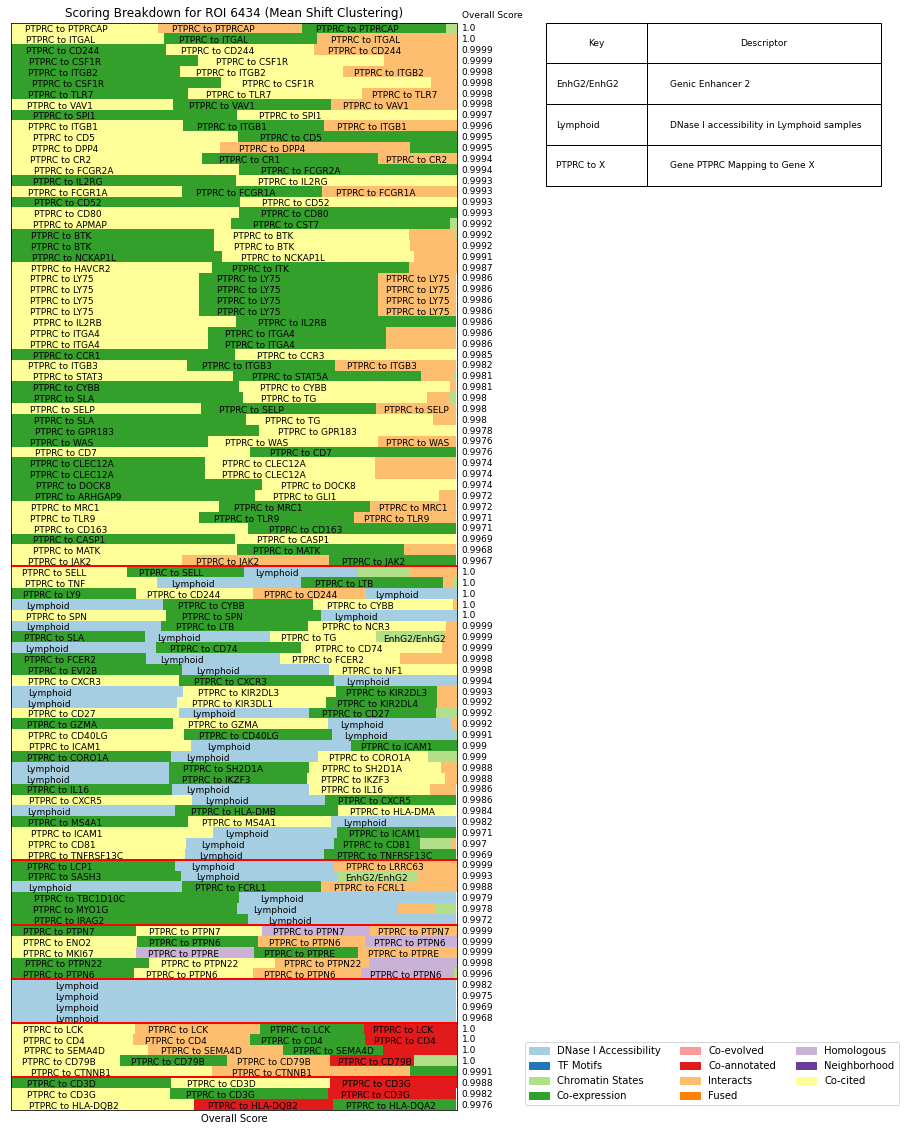

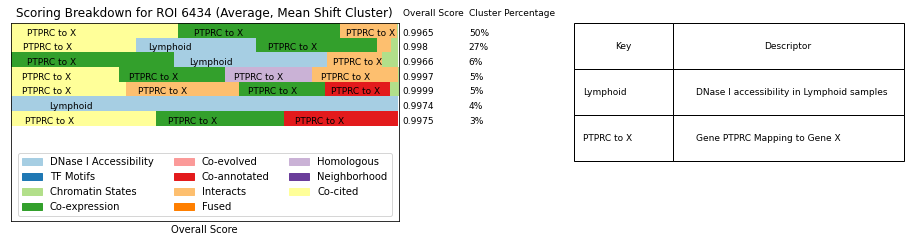

In [71]:
#sideways bar plots ordered by biggest component

metric_sum_top_100 = np.sum(all_metrics_arr_top_100, axis=0)
metrics_bar_scaled = all_metrics_arr_top_100 / metric_sum_top_100 * score_arr_top_100
metrics_bar_scaled_inds = np.argsort(-metrics_bar_scaled, axis=0)
metrics_bar_scaled_vals = -np.sort(-metrics_bar_scaled, axis=0)

colors = np.array(['#a6cee3', '#1f78b4', '#b2df8a', '#33a02c', '#fb9a99', '#e31a1c', '#fdbf6f', '#ff7f00', 
                   '#cab2d6', '#6a3d9a', '#ffff99'])

for r in range(len(roi))[:1]:
#     print(r)
#     t = time.time()
#     make_barplot(top_region_inds[r], metrics_bar_scaled_vals[:, r], metrics_bar_scaled_inds[:, r], 
#                  DHS_roi_rank[r], TF_roi_rank[r], epilogos_roi_mean_rank[r], epilogos_roi_max_rank[r], 
#                  DHS_ooe, TF_ooe, epilogos_ooe, DHS_component_order, TF_component_order, 
#                  epilogos_component_order, all_arr_ori[:, r], all_arr_dest[:, r], geneID2name, 
#                  score_arr_top_100[r], DHSfact2descr, TFfact2descr, epilogosfact2descr, roi[r], colors)
#     print('Total time =', time.time()-t)

    t = time.time()
    f0 = make_cluster_barplot(all_metrics_arr_top_100[:, r], top_region_inds[r], score_arr_top_100[r], all_arr_ori[:, r],
                         all_arr_dest[:, r], colors, DHS_roi_rank[r], TF_roi_rank[r], epilogos_roi_mean_rank[r], 
                         epilogos_roi_max_rank[r], DHS_ooe, TF_ooe, epilogos_ooe, DHS_component_order, 
                         TF_component_order, epilogos_component_order, geneID2name, DHSfact2descr, TFfact2descr, 
                         epilogosfact2descr, roi[r])
    print('Total time =', time.time()-t)

    t = time.time()
    f1 = make_reduced_barplot(all_metrics_arr_top_100[:, r], top_region_inds[r], all_arr_ori[:, r],
                         colors, DHS_roi_rank[r], TF_roi_rank[r], epilogos_roi_mean_rank[r], 
                         epilogos_roi_max_rank[r], DHS_ooe, TF_ooe, epilogos_ooe, DHS_component_order, 
                         TF_component_order, epilogos_component_order, geneID2name, DHSfact2descr, TFfact2descr, 
                         epilogosfact2descr, roi[r])
    print('Total time =', time.time()-t)

In [75]:
sys.stdout.write(f0.getvalue().decode('utf-8'))

<?xml version="1.0" encoding="utf-8" standalone="no"?>
<!DOCTYPE svg PUBLIC "-//W3C//DTD SVG 1.1//EN"
  "http://www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd">
<svg height="1440pt" version="1.1" viewBox="0 0 1152 1440" width="1152pt" xmlns="http://www.w3.org/2000/svg" xmlns:xlink="http://www.w3.org/1999/xlink">
 <metadata>
  <rdf:RDF xmlns:cc="http://creativecommons.org/ns#" xmlns:dc="http://purl.org/dc/elements/1.1/" xmlns:rdf="http://www.w3.org/1999/02/22-rdf-syntax-ns#">
   <cc:Work>
    <dc:type rdf:resource="http://purl.org/dc/dcmitype/StillImage"/>
    <dc:date>2022-08-31T13:35:40.726529</dc:date>
    <dc:format>image/svg+xml</dc:format>
    <dc:creator>
     <cc:Agent>
      <dc:title>Matplotlib v3.4.2, https://matplotlib.org/</dc:title>
     </cc:Agent>
    </dc:creator>
   </cc:Work>
  </rdf:RDF>
 </metadata>
 <defs>
  <style type="text/css">*{stroke-linecap:butt;stroke-linejoin:round;}</style>
 </defs>
 <g id="figure_1">
  <g id="patch_1">
   <path d="M 0 1440 
L 1152 1440 
L 115

518633

In [76]:
f0.getvalue()

b'<?xml version="1.0" encoding="utf-8" standalone="no"?>\n<!DOCTYPE svg PUBLIC "-//W3C//DTD SVG 1.1//EN"\n  "http://www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd">\n<svg height="1440pt" version="1.1" viewBox="0 0 1152 1440" width="1152pt" xmlns="http://www.w3.org/2000/svg" xmlns:xlink="http://www.w3.org/1999/xlink">\n <metadata>\n  <rdf:RDF xmlns:cc="http://creativecommons.org/ns#" xmlns:dc="http://purl.org/dc/elements/1.1/" xmlns:rdf="http://www.w3.org/1999/02/22-rdf-syntax-ns#">\n   <cc:Work>\n    <dc:type rdf:resource="http://purl.org/dc/dcmitype/StillImage"/>\n    <dc:date>2022-08-31T13:35:40.726529</dc:date>\n    <dc:format>image/svg+xml</dc:format>\n    <dc:creator>\n     <cc:Agent>\n      <dc:title>Matplotlib v3.4.2, https://matplotlib.org/</dc:title>\n     </cc:Agent>\n    </dc:creator>\n   </cc:Work>\n  </rdf:RDF>\n </metadata>\n <defs>\n  <style type="text/css">*{stroke-linecap:butt;stroke-linejoin:round;}</style>\n </defs>\n <g id="figure_1">\n  <g id="patch_1">\n   <path d="M 0

In [70]:
def make_reduced_barplot(all_metrics_arr_top_100, top_region_inds, all_arr_ori, colors, 
                         DHS_roi_rank, TF_roi_rank, epilogos_roi_mean_rank, epilogos_roi_max_rank, DHS_ooe, 
                         TF_ooe, epilogos_ooe, DHS_component_order, TF_component_order, epilogos_component_order, 
                         geneID2name, DHSfact2descr, TFfact2descr, epilogosfact2descr, roi):
    
    #sideways bar plots (average of each kmeans cluster)
    #cluster rows
    cluster = MeanShift()
    cluster.fit(all_metrics_arr_top_100.T)
    clusters_for_each_region = cluster.labels_

    # new_order_best_of_clusters = []
    cluster_percentages = np.array([])
    score_arr_top = np.array([])
    all_metrics_arr_top = []
    regions_per_cluster = [] #for labeling top factors
    for cluster_ind in np.unique(clusters_for_each_region):
        regions_in_cluster = np.where(clusters_for_each_region==cluster_ind)[0]
        regions_per_cluster.append(regions_in_cluster)
        cluster_percentages = np.append(cluster_percentages, int(len(regions_in_cluster)/len(clusters_for_each_region)*100)) #as percent
        cluster_scores = all_metrics_arr_top_100[:, regions_in_cluster]
        cluster_scores_mean = np.mean(cluster_scores, axis=1)
        score = 1 - np.prod(1 - cluster_scores_mean)
        score_arr_top = np.append(score_arr_top, score)
        all_metrics_arr_top.append(cluster_scores_mean)
    all_metrics_arr_top = np.array(all_metrics_arr_top).T
    regions_per_cluster = np.array(regions_per_cluster, dtype=object)

    #sorting
    # sort_order = np.argsort(-score_arr_top)
    sort_order = np.argsort(-cluster_percentages)
    all_metrics_arr_top = all_metrics_arr_top[:, sort_order]
    cluster_percentages = cluster_percentages[sort_order]
    score_arr_top = score_arr_top[sort_order]
    regions_per_cluster = regions_per_cluster[sort_order]

    metric_sum_top = np.sum(all_metrics_arr_top, axis=0)

    metrics_bar_scaled = all_metrics_arr_top / metric_sum_top * score_arr_top

    metrics_bar_scaled_inds = np.argsort(-metrics_bar_scaled, axis=0)
    metrics_bar_scaled_vals = -np.sort(-metrics_bar_scaled, axis=0)

    #plotting
    fig, axes = plt.subplots(ncols=2, figsize=(16, len(sort_order)*0.52))
    fig.patch.set_facecolor('white')
    plt.subplots_adjust(wspace=0.3)
    axes = axes.ravel()

    #sideways bar plot
    for i in range(11):
        axes[0].barh(np.flip(np.arange(len(score_arr_top))), 
                     metrics_bar_scaled_vals[i], 
                     left=np.sum(metrics_bar_scaled_vals[:i], axis=0), 
                     color=colors[metrics_bar_scaled_inds[i]], height=1, align='center')

    #label top comps
    top_factors = []
    for i in range(len(metrics_bar_scaled_vals[0])):
        start_val = 0
        regions_in_cluster = regions_per_cluster[i]
        for metric, val in zip(metrics_bar_scaled_inds[:, i], metrics_bar_scaled_vals[:, i]):
            if ((metric==0) & (val>0)):
                DHS_i_rank = rankdata(-np.mean(DHS_ooe[top_region_inds[1:][regions_in_cluster]], axis=0))
                top_comp = np.argsort((DHS_roi_rank+DHS_i_rank)/2)[0]
                if val / len(DHS_component_order[top_comp]) > 0.012:
                    axes[0].text(start_val + val/10, 
                             len(metrics_bar_scaled_vals[0])-1.35-i, 
                             DHS_component_order[top_comp], 
                             fontsize=9)
                    top_factors.append(DHS_component_order[top_comp])
            elif ((metric==1) & (val>0)):
                TF_i_rank = rankdata(-np.mean(TF_ooe[top_region_inds[1:][regions_in_cluster]], axis=0))
                top_comp = np.argsort((TF_roi_rank+TF_i_rank)/2)[0]
                if val / len(TF_component_order[top_comp]) > 0.012:
                    axes[0].text(start_val + val/10, 
                             len(metrics_bar_scaled_vals[0])-1.35-i, 
                             TF_component_order[top_comp], 
                             fontsize=9)
                    top_factors.append(TF_component_order[top_comp])
            elif ((metric==2) & (val>0)):
                epilogos_i_mean_rank = rankdata(-np.mean(epilogos_ooe[top_region_inds[1:][regions_in_cluster]][:, :18], axis=0))
                epilogos_i_max_rank = rankdata(-np.mean(epilogos_ooe[top_region_inds[1:][regions_in_cluster]][:, 18:], axis=0))
                top_mean_comp = np.argsort((epilogos_roi_mean_rank + epilogos_i_mean_rank)/2)[0]
                top_max_comp = np.argsort((epilogos_roi_max_rank + epilogos_i_max_rank)/2)[0]
                if val / len(epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp]) > 0.012:
                    axes[0].text(start_val + val/10, 
                             len(metrics_bar_scaled_vals[0])-1.35-i, 
                             epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp], 
                             fontsize=9)
                    top_factors.append(epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp])
            elif ((metric>2) & (val>0)):
                genes, counts = np.unique(all_arr_ori[:, regions_in_cluster][metric-3].astype(str), return_counts=True)
                genes_ordered = genes[np.argsort(-counts)]
                if genes_ordered[0] != 'None':
                    metric_ori_gene = geneID2name[genes_ordered[0]]
                else:
                    metric_ori_gene = geneID2name[genes_ordered[1]]
                if val / len(metric_ori_gene + ' to X') > 0.0135:
                    axes[0].text(start_val + val/10, 
                             len(metrics_bar_scaled_vals[0])-1.35-i, 
                             metric_ori_gene + ' to X', 
                             fontsize=9)
                    top_factors.append(metric_ori_gene + ' to X')
            start_val+=val

    #fusion scores and percent of top 100 in each cluster
    for i in range(len(metrics_bar_scaled_vals[0])):
        axes[0].text(1.01, 
                     len(metrics_bar_scaled_vals[0])-1.35-i, 
                     np.round(score_arr_top[i], 4), 
                     fontsize=9)
        axes[0].text(1.18, 
                     len(metrics_bar_scaled_vals[0])-1.35-i, 
                     str(int(cluster_percentages[i])) + '%', 
                     fontsize=9)

    axes[0].text(1.01, len(metrics_bar_scaled_vals[0]), 'Overall Score', fontsize=9)
    axes[0].text(1.18, len(metrics_bar_scaled_vals[0]), 'Cluster Percentage', fontsize=9)

    #look up table
    top_factors = np.unique(top_factors)
    factor_bar_arr = []
    for factor in top_factors:
        factor_l = factor.split('/')
        if len(factor_l) == 2: #epilogos
            if factor_l[0]==factor_l[1]:
                factor_bar_arr.append(epilogosfact2descr[factor_l[0]])
            else:
                factor_bar_arr.append(epilogosfact2descr[factor_l[0]] + ', with ' + epilogosfact2descr[factor_l[1]] + ' peaks')
        elif factor in DHSfact2descr: #DHS
            factor_bar_arr.append(DHSfact2descr[factor])
        elif factor in TFfact2descr: #TF motifs
            factor_bar_arr.append(factor + ': ' + TFfact2descr[factor])
        else:
            gene0, gene1 = factor.split(' to ')[0], factor.split(' to ')[1]
            factor_bar_arr.append('Gene ' + gene0 + ' Mapping to Gene X')
    factor_bar_arr = np.array(factor_bar_arr)
    lookup_table = np.hstack((top_factors.reshape((-1, 1)), factor_bar_arr.reshape((-1, 1))))
    t = axes[1].table(lookup_table, 
                      cellLoc='left',
                      colLabels=['Key', 'Descriptor'],
                      bbox=[0.15, 0.3, 0.85, 0.7], 
                      colWidths=[0.15, 0.35])
    t.auto_set_font_size(False)
    t.set_fontsize(9)

    axes[1].set_xticks([])
    axes[1].set_yticks([])

    axes[1].spines['right'].set_visible(False)
    axes[1].spines['left'].set_visible(False)
    axes[1].spines['top'].set_visible(False)
    axes[1].spines['bottom'].set_visible(False)

    axes[0].set_yticks([])
    axes[0].set_ylim([-7, len(all_metrics_arr_top[0])-0.5])
    axes[0].set_xticks([1])
    h = []

    for metric, c in zip(['DNase I Accessibility', 'TF Motifs', 'Chromatin States', 'Co-expression', 
                          'Co-evolved', 'Co-annotated', 'Interacts', 'Fused', 'Homologous', 
                          'Neighborhood', 'Co-cited'], colors):
        p = mpatches.Patch(color=c, label=metric)
        h.append(p)
    axes[0].legend(handles=h, loc='lower center', ncol=3)
    axes[0].set_xlabel('Overall Score')
    title = 'Scoring Breakdown for ROI %s (Average, Mean Shift Cluster)' %(roi)
    axes[0].set_title(title)
#     plt.savefig('/home/ctrader/region_similarity/data/figures/' + title.replace(' ', '_') + '_CT' + today.strftime("%Y%m%d") + '.pdf', 
#                 bbox_inches='tight', 
#                 dpi=400, 
#                 facecolor="#FFFFFF", 
#                 edgecolor="#FFFFFF", 
#                 transparent=False)
#     plt.savefig('/home/ctrader/region_similarity/data/figures/' + title.replace(' ', '_') + '_SVG_test_CT' + today.strftime("%Y%m%d") + '.svg')
#     plt.show()
    f = io.BytesIO()
    plt.savefig(f, format='svg')
#     sys.stdout.write(fig)
    return f

In [63]:
def make_cluster_barplot(all_metrics_arr_top_100, top_region_inds, score_arr_top_100, all_arr_ori, all_arr_dest, colors, 
                         DHS_roi_rank, TF_roi_rank, epilogos_roi_mean_rank, epilogos_roi_max_rank, DHS_ooe, 
                         TF_ooe, epilogos_ooe, DHS_component_order, TF_component_order, epilogos_component_order, 
                         geneID2name, DHSfact2descr, TFfact2descr, epilogosfact2descr, roi):
    #sideways bar plots (by clustering order)
    #cluster rows and get new order for regions
    cluster = MeanShift()
    cluster.fit(all_metrics_arr_top_100.T)
    cluster_labels = cluster.labels_
    new_order_top_100 = np.array([], dtype=int)
    for c in np.unique(cluster_labels):
        new_order_top_100 = np.append(new_order_top_100, np.where(cluster_labels==c)[0])

    #re-order
    all_metrics_arr_top_100_reordered = all_metrics_arr_top_100[:, new_order_top_100]
    top_region_inds_reordered = np.append(top_region_inds[0], top_region_inds[1:][new_order_top_100])
    score_arr_top_100 = score_arr_top_100[new_order_top_100]
    
    metric_sum_top_100 = np.sum(all_metrics_arr_top_100_reordered, axis=0)
    metrics_bar_scaled = all_metrics_arr_top_100_reordered / metric_sum_top_100 * score_arr_top_100 

    metrics_bar_scaled_inds = np.argsort(-metrics_bar_scaled, axis=0)
    metrics_bar_scaled_vals = -np.sort(-metrics_bar_scaled, axis=0)

    #all string original and destination genes
    all_arr_ori = all_arr_ori[:, new_order_top_100]
    all_arr_dest = all_arr_dest[:, new_order_top_100]

    #plotting
    fig, axes = plt.subplots(ncols=2, figsize=(16, 20))
    fig.patch.set_facecolor('white')
    plt.subplots_adjust(wspace=0)
    axes = axes.ravel()

    #sideways bar plot
    for i in range(11):
        axes[0].barh(np.flip(np.arange(100)), metrics_bar_scaled_vals[i], left=np.sum(metrics_bar_scaled_vals[:i], axis=0), 
                 color=colors[metrics_bar_scaled_inds[i]], height=1, align='center')

    #label top comps
    top_factors = []
    for i in range(len(metrics_bar_scaled_vals[0])):
        start_val = 0
        for metric, val in zip(metrics_bar_scaled_inds[:, i], metrics_bar_scaled_vals[:, i]):
            if ((metric==0) & (val>0)):
                DHS_i_rank = rankdata(-DHS_ooe[top_region_inds_reordered[i+1]])
                top_comp = np.argsort((DHS_roi_rank+DHS_i_rank)/2)[0]
                if val / len(DHS_component_order[top_comp]) > 0.012:
                    axes[0].text(start_val + val/10, 
                             len(metrics_bar_scaled_vals[0])-1.35-i, 
                             DHS_component_order[top_comp], 
                             fontsize=9)
                    top_factors.append(DHS_component_order[top_comp])
            elif ((metric==1) & (val>0)):
                TF_i_rank = rankdata(-TF_ooe[top_region_inds_reordered[i+1]])
                top_comp = np.argsort((TF_roi_rank+TF_i_rank)/2)[0]
                if val / len(TF_component_order[top_comp]) > 0.012:
                    axes[0].text(start_val + val/10, 
                             len(metrics_bar_scaled_vals[0])-1.35-i, 
                             TF_component_order[top_comp], 
                             fontsize=9)
                    top_factors.append(TF_component_order[top_comp])
            elif ((metric==2) & (val>0)):
                epilogos_i_mean_rank = rankdata(-epilogos_ooe[top_region_inds_reordered[i+1]][:18])
                epilogos_i_max_rank = rankdata(-epilogos_ooe[top_region_inds_reordered[i+1]][18:])
                top_mean_comp = np.argsort((epilogos_roi_mean_rank + epilogos_i_mean_rank)/2)[0]
                top_max_comp = np.argsort((epilogos_roi_max_rank + epilogos_i_max_rank)/2)[0]
                if val / len(epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp]) > 0.012:
                    axes[0].text(start_val + val/10, 
                             len(metrics_bar_scaled_vals[0])-1.35-i, 
                             epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp], 
                             fontsize=9)
                    top_factors.append(epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp])
            elif ((metric>2) & (val>0)):
                metric_ori_gene = geneID2name[all_arr_ori[metric-3][i]]
                metric_dest_gene = geneID2name[all_arr_dest[metric-3][i]]
                if val / len(metric_ori_gene + ' to ' + metric_dest_gene) > 0.0135:
                    axes[0].text(start_val + val/10, 
                             len(metrics_bar_scaled_vals[0])-1.35-i, 
                             metric_ori_gene + ' to ' + metric_dest_gene, 
                             fontsize=9)
                    top_factors.append(metric_ori_gene + ' to X')
            start_val+=val
        axes[1].text(0.01, 
                     (len(metrics_bar_scaled_vals[0])-0.75-i)/len(metrics_bar_scaled_vals[0]), 
                     np.round(score_arr_top_100[i], 4), 
                     fontsize=9)

    axes[1].text(0.01, 1.005, 'Overall Score', fontsize=9)

    #Seperating Clusters with black lines
    height = len(metrics_bar_scaled_vals[0])-0.5
    for c in np.unique(cluster_labels)[:-1]: #not inclding line at bottom
        num_in_cluster = len(cluster_labels[cluster_labels==c])
        height -= num_in_cluster
        axes[0].plot([0, 1], [height, height], c='r', linewidth=2)

    #look up table
    top_factors = np.unique(top_factors)
    factor_bar_arr = []
    for factor in top_factors:
        factor_l = factor.split('/')
        if len(factor_l) == 2: #epilogos
            if factor_l[0]==factor_l[1]:
                factor_bar_arr.append(epilogosfact2descr[factor_l[0]])
            else:
                factor_bar_arr.append(epilogosfact2descr[factor_l[0]] + ', with ' + epilogosfact2descr[factor_l[1]] + ' peaks')
        elif factor in DHSfact2descr: #DHS
            factor_bar_arr.append(DHSfact2descr[factor])
        elif factor in TFfact2descr: #TF motifs
            factor_bar_arr.append(factor + ': ' + TFfact2descr[factor])
        else:
            gene0, _ = factor.split(' to ')[0], factor.split(' to ')[1]
            factor_bar_arr.append('Gene ' + gene0 + ' Mapping to Gene X')
    factor_bar_arr = np.array(factor_bar_arr)
    lookup_table = np.hstack((top_factors.reshape((-1, 1)), factor_bar_arr.reshape((-1, 1))))
    t = axes[1].table(lookup_table, 
                  cellLoc='left',
                  colLabels=['Key', 'Descriptor'],
                  bbox=[0.2, 1-(len(factor_bar_arr)/20), 0.75, (len(factor_bar_arr)/20)], 
                  colWidths=[0.15, 0.35])
    t.auto_set_font_size(False)
    t.set_fontsize(9)

    axes[1].set_xticks([])
    axes[1].set_yticks([])

    axes[1].spines['right'].set_visible(False)
    # axes[1].spines['left'].set_visible(False)
    axes[1].spines['top'].set_visible(False)
    axes[1].spines['bottom'].set_visible(False)

    axes[0].set_yticks([])
    axes[0].set_ylim([-0.5, 99.5])
    axes[0].set_xticks([1])
    h = []

    for metric, c in zip(['DNase I Accessibility', 'TF Motifs', 'Chromatin States', 'Co-expression', 
                          'Co-evolved', 'Co-annotated', 'Interacts', 'Fused', 'Homologous', 
                          'Neighborhood', 'Co-cited'], colors):
        p = mpatches.Patch(color=c, label=metric)
        h.append(p)
    axes[1].legend(handles=h, loc='lower right', ncol=3)
    axes[0].set_xlabel('Overall Score')
    title = 'Scoring Breakdown for ROI %s (Mean Shift Clustering)' %(roi)
    axes[0].set_title(title)
    # plt.savefig('/home/ctrader/region_similarity/data/figures/' + title.replace(' ', '_') + '_CT' + today.strftime("%Y%m%d") + '.pdf', 
    #             bbox_inches='tight', 
    #             dpi=400, 
    #             facecolor="#FFFFFF", 
    #             edgecolor="#FFFFFF", 
    #             transparent=False)
#     plt.show()
#     plt.savefig('/home/ctrader/region_similarity/data/figures/' + title.replace(' ', '_') + '_SVG_test_CT' + today.strftime("%Y%m%d") + '.svg')
    f = io.BytesIO()
    plt.savefig(f, format='svg')
    return f

In [17]:
def make_barplot(top_region_inds, metrics_bar_scaled_vals, metrics_bar_scaled_inds, DHS_roi_rank, TF_roi_rank, 
                 epilogos_roi_mean_rank, epilogos_roi_max_rank, DHS_ooe, TF_ooe, epilogos_ooe, 
                 DHS_component_order, TF_component_order, epilogos_component_order, all_arr_ori, all_arr_dest, 
                 geneID2name, score_arr_top_100, DHSfact2descr, TFfact2descr, epilogosfact2descr, roi, colors):
    #plotting
    fig, axes = plt.subplots(ncols=2, figsize=(16, 20))
    fig.patch.set_facecolor('white')
    axes = axes.ravel()
    
    for i in range(len(metrics_bar_scaled_vals)):
        axes[0].barh(np.flip(np.arange(100)), metrics_bar_scaled_vals[i], left=np.sum(metrics_bar_scaled_vals[:i], axis=0), 
                     color=colors[metrics_bar_scaled_inds[i]], height=1, align='center')
        
    #label top comps
    top_factors = []
    for i in range(len(metrics_bar_scaled_vals[0])):
        start_val = 0
        for metric, val in zip(metrics_bar_scaled_inds[:, i], metrics_bar_scaled_vals[:, i]):
            if ((metric==0) & (val>0)):
                DHS_i_rank = rankdata(-DHS_ooe[top_region_inds[i+1]])
                top_comp = np.argsort((DHS_roi_rank+DHS_i_rank)/2)[0]
                if val / len(DHS_component_order[top_comp]) > 0.012:
                    axes[0].text(start_val + val/10, 
                             len(metrics_bar_scaled_vals[0])-1.35-i, 
                             DHS_component_order[top_comp], 
                             fontsize=9)
                    top_factors.append(DHS_component_order[top_comp])
            elif ((metric==1) & (val>0)):
                TF_i_rank = rankdata(-TF_ooe[top_region_inds[i+1]])
                top_comp = np.argsort((TF_roi_rank+TF_i_rank)/2)[0]
                if val / len(TF_component_order[top_comp]) > 0.012:
                    axes[0].text(start_val + val/10, 
                             len(metrics_bar_scaled_vals[0])-1.35-i, 
                             TF_component_order[top_comp], 
                             fontsize=9)
                    top_factors.append(TF_component_order[top_comp])
            elif ((metric==2) & (val>0)):
                epilogos_i_mean_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][:18])
                epilogos_i_max_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][18:])
                top_mean_comp = np.argsort((epilogos_roi_mean_rank + epilogos_i_mean_rank)/2)[0]
                top_max_comp = np.argsort((epilogos_roi_max_rank + epilogos_i_max_rank)/2)[0]
                if val / len(epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp]) > 0.012:
                    axes[0].text(start_val + val/10, 
                             len(metrics_bar_scaled_vals[0])-1.35-i, 
                             epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp], 
                             fontsize=9)
                    top_factors.append(epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp])
            elif ((metric>2) & (val>0)):
                metric_ori_gene = geneID2name[all_arr_ori[metric-3][i]]
                metric_dest_gene = geneID2name[all_arr_dest[metric-3][i]]
                if val / len(metric_ori_gene + ' to ' + metric_dest_gene) > 0.0135:
                    axes[0].text(start_val + val/10, 
                             len(metrics_bar_scaled_vals[0])-1.35-i, 
                             metric_ori_gene + ' to ' + metric_dest_gene, 
                             fontsize=9)
                    top_factors.append(metric_ori_gene + ' to X')
            start_val+=val
        axes[0].text(1.01, 
             len(metrics_bar_scaled_vals[0])-1.35-i, 
             np.round(score_arr_top_100[i], 4), 
             fontsize=9)
    axes[0].text(1.01, len(metrics_bar_scaled_vals[0]), 'Overall Score', fontsize=9)
    
    #look up table
    top_factors = np.unique(top_factors)
    factor_bar_arr = []
    for factor in top_factors:
        factor_l = factor.split('/')
        if len(factor_l) == 2: #epilogos
            if factor_l[0]==factor_l[1]:
                factor_bar_arr.append(epilogosfact2descr[factor_l[0]])
            else:
                factor_bar_arr.append(epilogosfact2descr[factor_l[0]] + ', with ' + epilogosfact2descr[factor_l[1]] + ' peaks')
        elif factor in DHSfact2descr: #DHS
            factor_bar_arr.append(DHSfact2descr[factor])
        elif factor in TFfact2descr: #TF motifs
            factor_bar_arr.append(factor + ': ' + TFfact2descr[factor])
        else:
            gene0, gene1 = factor.split(' to ')[0], factor.split(' to ')[1]
            factor_bar_arr.append('Gene ' + gene0 + ' Mapping to Gene X')
    factor_bar_arr = np.array(factor_bar_arr)
    lookup_table = np.hstack((top_factors.reshape((-1, 1)), factor_bar_arr.reshape((-1, 1))))
    t = axes[1].table(lookup_table, 
                      cellLoc='left',
                      colLabels=['Key', 'Descriptor'],
#                       bbox=[0, 0.3, 0.95, 0.7], 
                      bbox=[0.2, 1-(len(factor_bar_arr)/20), 0.75, (len(factor_bar_arr)/20)],
                      colWidths=[0.15, 0.35])
    t.auto_set_font_size(False)
    t.set_fontsize(9)

    axes[1].set_xticks([])
    axes[1].set_yticks([])

    axes[1].spines['right'].set_visible(False)
    axes[1].spines['left'].set_visible(False)
    axes[1].spines['top'].set_visible(False)
    axes[1].spines['bottom'].set_visible(False)

    axes[0].set_yticks(np.arange(9, 101, 10))
    axes[0].set_yticklabels(np.flip(np.arange(1, 92, 10)))
    axes[0].set_ylim([-10, 99.5])
    axes[0].set_xticks([1])
    h = []

    for metric, c in zip(['DNase I Accessibility', 'TF Motifs', 'Chromatin States', 'Co-expression', 
                          'Co-evolved', 'Co-annotated', 'Interacts', 'Fused', 'Homologous', 
                          'Neighborhood', 'Co-cited'], colors):
        p = mpatches.Patch(color=c, label=metric)
        h.append(p)
    axes[0].legend(handles=h, loc='lower center', ncol=3)
    axes[0].set_xlabel('Overall Score')
    axes[0].set_ylabel('Recommended Region')
    title = 'Scoring Breakdown for ROI %s' %(roi)
    axes[0].set_title(title)
#     plt.savefig('/home/ctrader/region_similarity/data/figures/' + title.replace(' ', '_') + '_CT' + today.strftime("%Y%m%d") + '.pdf', 
#                 bbox_inches='tight', 
#                 dpi=400, 
#                 facecolor="#FFFFFF", 
#                 edgecolor="#FFFFFF", 
#                 transparent=False)

#     plt.show()
    return

In [ ]:
def make_spectrum_plot(roi, gene_set_order, inds_clustered, sig_file_path, all_file_path, 
                      regions_path):
    #gene set spectrum plot
    hdf5_file = h5py.File(sig_file_path, 'r')
    gene_set_sig_log2ooe = hdf5_file['sig_gene_set_roi_log2ooe'][roi][inds_clustered][gene_set_order]
    gene_set_sig_counts = hdf5_file['sig_gene_set_roi_counts'][roi][inds_clustered][gene_set_order]
    hdf5_file.close()
    
    hdf5_file = h5py.File(all_file_path, 'r')
    gene_sets = np.char.decode(hdf5_file['gene_sets'][:], 'utf-8')[inds_clustered][gene_set_order]
    hdf5_file.close()
    
    colors = cm.get_cmap('nipy_spectral', len(gene_set_order))
    
    #max over a given window size
    window_size = 20
    gene_set_sig_log2ooe_windowed = np.array([])
    for i in range(len(gene_set_sig_log2ooe)):
        gene_set_sig_log2ooe_windowed = np.append(gene_set_sig_log2ooe_windowed, 
                                                  np.max(gene_set_sig_log2ooe[max(i-int(window_size/2), 0):
                                                                              min(i+int(window_size/2), 
                                                                                  len(gene_set_sig_log2ooe))]))
    #smoothing with mean
    gene_set_sig_log2ooe_windowed_smoothed = np.array([])
    for i in range(len(gene_set_sig_log2ooe_windowed)):
        gene_set_sig_log2ooe_windowed_smoothed = np.append(gene_set_sig_log2ooe_windowed_smoothed, 
                                                           np.mean(gene_set_sig_log2ooe_windowed[max(i-int(window_size/2), 0):
                                                                                                 min(i+int(window_size/2), 
                                                                                                     len(gene_set_sig_log2ooe_windowed))]))
    
    cluster_inds_sorted = np.where(gene_set_sig_log2ooe!=0)[0]
    gene_sets_labels_ordered = gene_sets[cluster_inds_sorted]
    gene_sets_vals_ordered = gene_set_sig_log2ooe[cluster_inds_sorted]
    
    gene_sets_to_label = np.array([])
    cluster_inds_to_label = np.array([])
    vals_to_label = np.array([])
    for cluster_ind, label, val in zip(cluster_inds_sorted, gene_sets_labels_ordered, gene_sets_vals_ordered):
        label = ' '.join(label.split('_'))
        if len(vals_to_label) == 0:
            gene_sets_to_label = np.append(gene_sets_to_label, label)
            cluster_inds_to_label = np.append(cluster_inds_to_label, cluster_ind)
            vals_to_label = np.append(vals_to_label, val)
        elif ((cluster_ind - cluster_inds_to_label[-1] <= 100) & (vals_to_label[-1] < val)):
            gene_sets_to_label[-1] = label
            cluster_inds_to_label[-1] = cluster_ind
            vals_to_label[-1] = val
        elif cluster_ind - cluster_inds_to_label[-1] > 100:
            gene_sets_to_label = np.append(gene_sets_to_label, label)
            cluster_inds_to_label = np.append(cluster_inds_to_label, cluster_ind)
            vals_to_label = np.append(vals_to_label, val)
            
    #trimming terms
    for i in range(len(gene_sets_to_label)):
        gene_sets_to_label[i] = gene_sets_to_label[i].replace('WP ', '').replace('HALLMARK ', '').replace('KEGG ', '').replace('REACTOME ', '').replace('BIOCARTA ', '')

    #plot
    fig, axes = plt.subplots(nrows=2, gridspec_kw={'height_ratios': [4, 1]}, figsize=(12, 2))
    fig.patch.set_facecolor('white')
    axes = axes.ravel()
    plt.subplots_adjust(hspace=0)

    axes[0].fill_between(range(len(gene_set_sig_log2ooe_windowed_smoothed)), 
                         gene_set_sig_log2ooe_windowed_smoothed, color='k')

    colorbar.ColorbarBase(axes[1], cmap=colors, orientation='horizontal').set_ticks(cluster_inds_to_label/len(gene_sets))
    axes[0].set_xlim([0, len(gene_sets)])
    axes[0].set_xticks([])
    axes[0].set_ylabel('Windowed Enrichment')
    axes[0].set_ylim([0, np.max(gene_set_sig_log2ooe_windowed)*1.1])
    axes[1].set_xticklabels(gene_sets_to_label, rotation=45, ha='right')

    for xlabel, size in zip(axes[1].xaxis.get_ticklabels(), vals_to_label):
        xlabel.set_fontsize(size*2.5)


    f = open(regions_path, 'r')
    regions = f.readlines()
    f.close()
    regions = regions[roi].strip().split('\t')
    genome_coords = regions[0] + ':' + regions[1] + '-' + regions[2]

#     title = 'Smoothed Windowed Enrichment of Significant OOE Gene Sets for ROI %s\n(%s) and Top 100 Regions' %(roi, genome_coords)
#     fig.suptitle(title, y=1.08)
#     plt.savefig('/home/ctrader/region_similarity/data/figures/' + title.replace(' ', '_').replace(':', '').replace('(', '').replace(')', '').replace('\n', '_') + '_CT' + today.strftime("%Y%m%d") + '.pdf', 
#                 bbox_inches='tight', 
#                 dpi=400, 
#                 facecolor="#FFFFFF", 
#                 edgecolor="#FFFFFF", 
#                 transparent=False)
    return

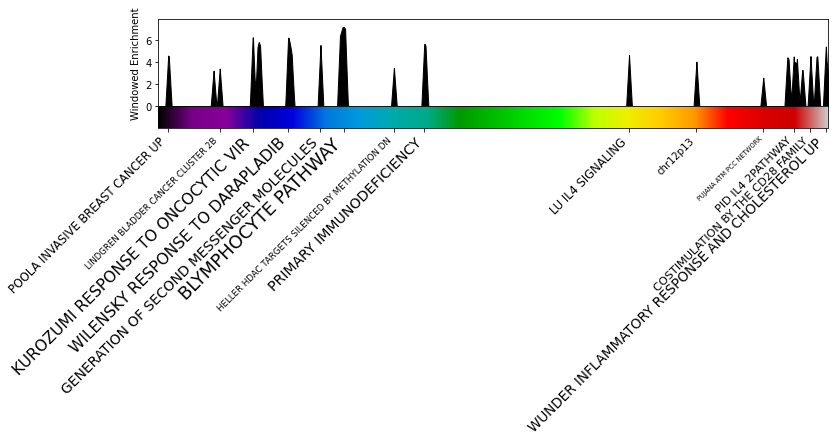

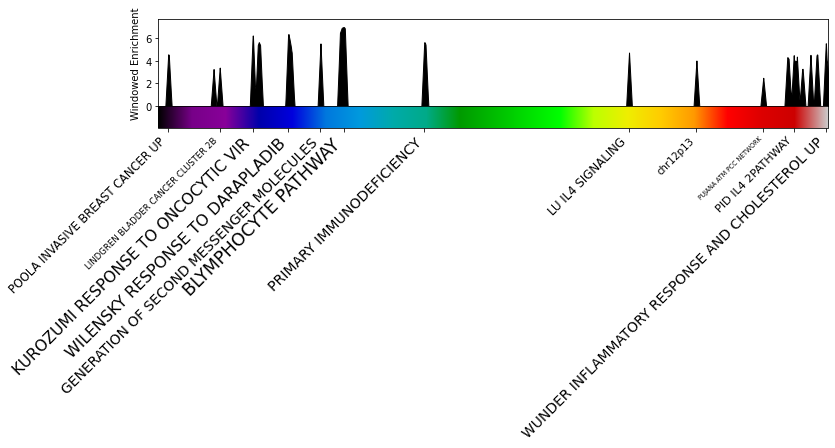

In [12]:
gene_set_order_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220817.genesethallmarkc1c2order.cosine.average.npz'
gene_set_order = np.load(gene_set_order_path)['gene_set_order']
inds_clustered = np.load(gene_set_order_path)['inds_clustered']

sig_file_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220817.genesethallmarkc1c2freqooe.sig.hdf5'
all_file_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220817.genesethallmarkc1c2freqooe.hdf5'
regions_path = '/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220815.sorted.c1t3.bed'

for r in range(len(roi)):
    make_spectrum_plot(roi[r], gene_set_order, inds_clustered, sig_file_path, 
                       all_file_path, regions_path)

In [81]:
def make_full_upset(top_region_inds, DHS_arr_top_100, TF_arr_top_100, 
                    epilogos_arr_top_100, string_arr_top_100, DHS_ooe, TF_ooe, 
                    epilogos_ooe, DHS_roi_rank, TF_roi_rank, epilogos_roi_mean_rank, 
                    epilogos_roi_max_rank, DHS_component_order, TF_component_order, 
                    epilogos_component_order, string_comp_order, DHSfact2descr, 
                    TFfact2descr, epilogosfact2descr, geneID2name, all_arr_ori, colors, 
                    regions_path, roi):
    
    color_tracker = np.array([])
    topfactor2region = {}
    #find top comps for each metric/recommended region
    for i in range(len(DHS_arr_top_100)):
        if DHS_arr_top_100[i] > 0:
            DHS_i_rank = rankdata(-DHS_ooe[top_region_inds[i+1]])
            top_comp = np.argsort((DHS_roi_rank+DHS_i_rank)/2)[0]
            f = DHSfact2descr[DHS_component_order[top_comp]]
            if f not in topfactor2region:
                topfactor2region[f] = np.array([i])
                color_tracker = np.append(color_tracker, colors[0])
            else:
                topfactor2region[f] = np.append(topfactor2region[f], [i])
    
    for i in range(len(TF_arr_top_100)):
        if TF_arr_top_100[i] > 0:
            TF_i_rank = rankdata(-TF_ooe[top_region_inds[i+1]])
            top_comp = np.argsort((TF_roi_rank+TF_i_rank)/2)[0]
            f = TF_component_order[top_comp] + ': ' + TFfact2descr[TF_component_order[top_comp]]
            if f not in topfactor2region:
                topfactor2region[f] = np.array([i])
                color_tracker = np.append(color_tracker, colors[1])
            else:
                topfactor2region[f] = np.append(topfactor2region[f], [i])
    
    for i in range(len(epilogos_arr_top_100)):
        if epilogos_arr_top_100[i] > 0:
            epilogos_i_mean_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][:18])
            epilogos_i_max_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][18:])
            top_mean_comp = np.argsort((epilogos_roi_mean_rank + epilogos_i_mean_rank)/2)[0]
            top_max_comp = np.argsort((epilogos_roi_max_rank + epilogos_i_max_rank)/2)[0]
            if top_mean_comp==top_max_comp:
                f = epilogosfact2descr[epilogos_component_order[top_mean_comp]]
            else:
                f = (epilogosfact2descr[epilogos_component_order[top_mean_comp]] + ', with ' + 
                     epilogosfact2descr[epilogos_component_order[top_max_comp]] + ' peaks')
            if f not in topfactor2region:
                topfactor2region[f] = np.array([i])
                color_tracker = np.append(color_tracker, colors[2])
            else:
                topfactor2region[f] = np.append(topfactor2region[f], [i])
    
    #STRING Scores
    for i in range(len(string_arr_top_100[0, :])):
        if np.sum(string_arr_top_100[:, i]) > 0:
            pos_string_inds = np.where(string_arr_top_100[:, i]>0)[0]
            for comp in pos_string_inds:
                ori_gene = geneID2name[all_arr_ori[comp, i]]
                f = 'Gene ' + string_comp_order[comp] + ' ' + ori_gene
                if f not in topfactor2region:
                    topfactor2region[f] = np.array([i])
                    color_tracker = np.append(color_tracker, colors[comp+3])
                else:
                    topfactor2region[f] = np.append(topfactor2region[f], [i])
                
    upset_data = upsetplot.from_contents(topfactor2region)
    upset_data = upset_data.groupby(list(upset_data.index.names)).count()['id']

    #sorting upset categories
    upset_factors = np.array(upset_data.index.names)
    upset_factor_counts = np.array([])
    for i in range(len(upset_factors)):
        upset_factor_counts = np.append(upset_factor_counts, np.sum(upset_data.unstack(level=i)[True]))
    upset_factors_sorted = upset_factors[np.argsort(upset_factor_counts)]
    sorted_upset_data = upset_data.reorder_levels(upset_factors_sorted)
    color_tracker_sorted = color_tracker[np.argsort(upset_factor_counts)]
    
    fig = plt.figure(figsize=(20,10))
    u = upsetplot.plot(sorted_upset_data, 
                       sort_categories_by=None, 
                       show_counts=True, 
                       min_subset_size=1, 
                       sort_by='cardinality', 
                       element_size=50)

    ###setting label colors to match bar plots
    for label, c in zip(u['matrix'].yaxis.get_ticklabels(), color_tracker_sorted):
        label.set_backgroundcolor(c)

    f = open(regions_path, 'r')
    regions = f.readlines()
    regions = regions[roi].strip().split('\t')
    genome_coords = regions[0] + ':' + regions[1] + '-' + regions[2]
    f.close()

    plt.ylabel('Number of Regions')
    title='Breakdown of Factors with Top 100 Regions for ROI %s (%s)' %(roi, genome_coords)
    plt.suptitle(title, fontsize=18)
    print(title)
    plt.savefig('/home/ctrader/region_similarity/data/figures/' + title.replace(' ', '_').replace(':', '').replace('(', '').replace(')', '').replace('\n', '_') + '_CT' + today.strftime("%Y%m%d") + '.pdf', 
                bbox_inches='tight', 
                dpi=400, 
                facecolor="#FFFFFF", 
                edgecolor="#FFFFFF", 
                transparent=False)
    return sorted_upset_data, topfactor2region, color_tracker_sorted

def make_limited_upset(limiting_per, sorted_upset_data, topfactor2region, 
                       color_tracker_sorted, regions_path, roi):
    overall_set = set()
    topfactor2region_limited = {}
    ind = 0
    while len(overall_set) < limiting_per:
        factor = np.flip(list(sorted_upset_data.index.names))[ind]
        factor_set = set(list(topfactor2region[factor]))
        overall_set.update(factor_set)
        ind += 1
        topfactor2region_limited[factor] = topfactor2region[factor]
    
    upset_data_limited = upsetplot.from_contents(topfactor2region_limited)
    upset_data_limited = upset_data_limited.groupby(list(upset_data_limited.index.names)).count()['id']
    
    if len(topfactor2region_limited) > 1: #more than 1 factor
        #sorting upset categories
        upset_factors_limited = np.array(upset_data_limited.index.names)
        upset_factor_counts_limited = np.array([])

        for i in range(len(upset_factors_limited)):
            upset_factor_counts_limited = np.append(upset_factor_counts_limited, np.sum(upset_data_limited.unstack(level=i)[True]))
        upset_factors_sorted_limited = upset_factors_limited[np.argsort(upset_factor_counts_limited)]
        sorted_upset_data_limited = upset_data_limited.reorder_levels(upset_factors_sorted_limited)

        fig = plt.figure(figsize=(20,10))

        u = upsetplot.plot(sorted_upset_data_limited, 
                           sort_categories_by=None, 
                           show_counts=True, 
                           min_subset_size=1, 
                           sort_by='cardinality', 
                           element_size=50)

        ###setting label colors to match bar plots
        for label, c in zip(u['matrix'].yaxis.get_ticklabels(), color_tracker_sorted[-len(upset_factors_sorted_limited):]):
            label.set_backgroundcolor(c)

        f = open(regions_path, 'r')
        regions = f.readlines()
        regions = regions[roi].strip().split('\t')
        genome_coords = regions[0] + ':' + regions[1] + '-' + regions[2]
        f.close()

        plt.ylabel('Number of Regions')
        title='Factors Describing ' + str(limiting_per) + '%' + ' of Top 100 Regions\nfor ROI %s (%s)' %(roi, genome_coords)
        plt.suptitle(title, fontsize=18)
        print(title)
        plt.savefig('/home/ctrader/region_similarity/data/figures/' + title.replace(' ', '_').replace(':', '').replace('(', '').replace(')', '').replace('\n', '_') + '_CT' + today.strftime("%Y%m%d") + '.pdf', 
                    bbox_inches='tight', 
                    dpi=400, 
                    facecolor="#FFFFFF", 
                    edgecolor="#FFFFFF", 
                    transparent=False)
    return


Breakdown of Factors with Top 100 Regions for ROI 6434 (chr1:198632800-198657800)
Factors Describing 98% of Top 100 Regions
for ROI 6434 (chr1:198632800-198657800)
Breakdown of Factors with Top 100 Regions for ROI 6435 (chr1:198657800-198682800)


<Figure size 1440x720 with 0 Axes>

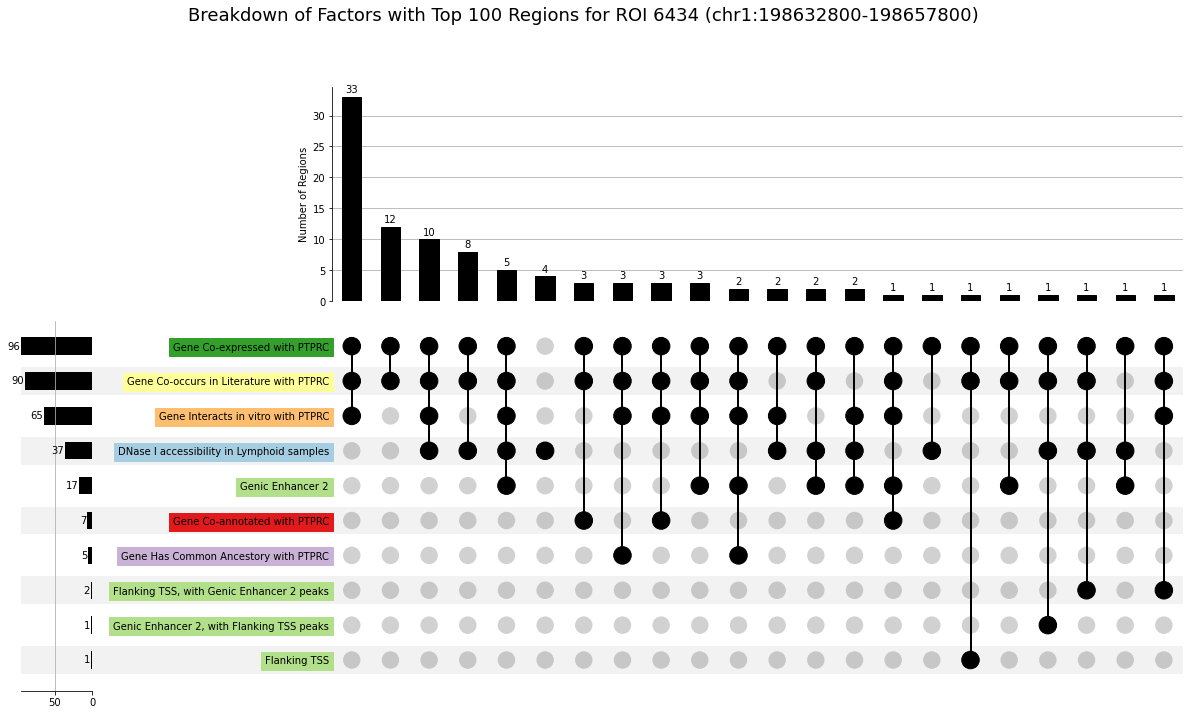

<Figure size 1440x720 with 0 Axes>

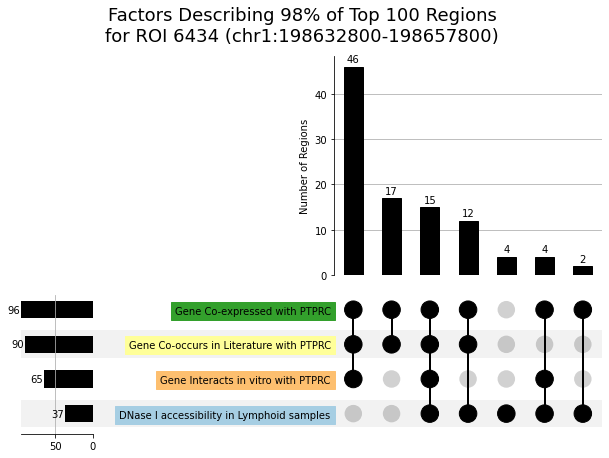

<Figure size 1440x720 with 0 Axes>

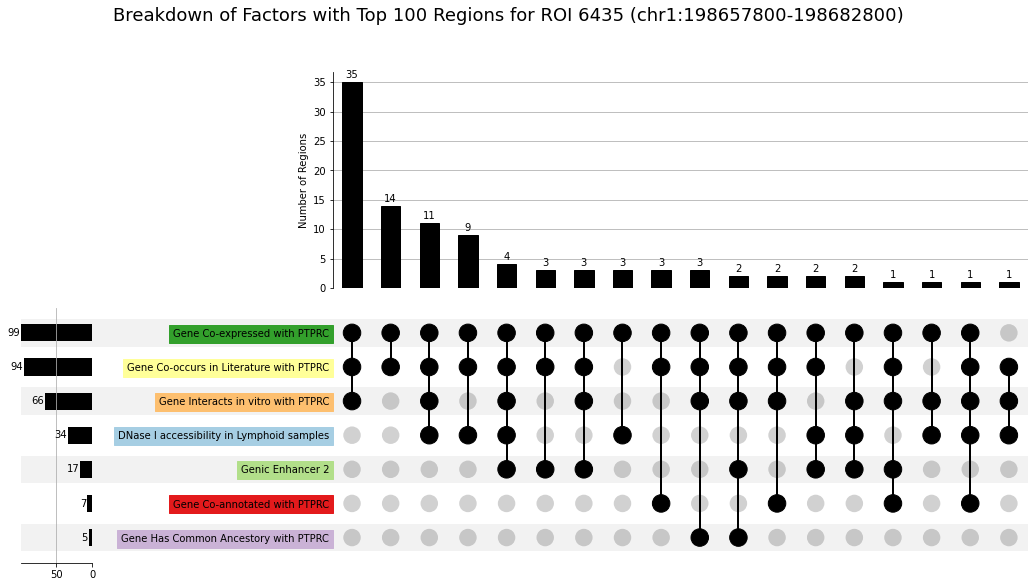

In [82]:
#make upset plots
colors = np.array(['#a6cee3', '#1f78b4', '#b2df8a', '#33a02c', '#fb9a99', '#e31a1c', '#fdbf6f', '#ff7f00', 
                   '#cab2d6', '#6a3d9a', '#ffff99'])
string_comp_order = ['Co-expressed with', 'Co-occurs within Species with', 'Co-annotated with', 
                     'Interacts in vitro with', 'Fused in Other Species with', 'Has Common Ancestory with', 
                     'is Nearby', 'Co-occurs in Literature with']
limiting_per = 98
for r in range(len(roi)):
    (sorted_upset_data, 
     topfactor2region, 
     color_tracker_sorted) = make_full_upset(top_region_inds[r], DHS_arr_top_100[r], 
                                             TF_arr_top_100[r], epilogos_arr_top_100[r], 
                                             string_arr_top_100[:, r], DHS_ooe, TF_ooe, 
                                             epilogos_ooe, DHS_roi_rank[r], TF_roi_rank[r], 
                                             epilogos_roi_mean_rank[r], epilogos_roi_max_rank[r], 
                                             DHS_component_order, TF_component_order, 
                                             epilogos_component_order, string_comp_order, 
                                             DHSfact2descr, TFfact2descr, epilogosfact2descr, 
                                             geneID2name, all_arr_ori[:, r], colors, 
                                             regions_path, roi[r])
    make_limited_upset(limiting_per, sorted_upset_data, topfactor2region, 
                       color_tracker_sorted, regions_path, roi[r])

In [66]:
roi[r]

6435

In [64]:
roi.shape

(2,)

In [78]:
# file = open('/home/ctrader/region_similarity/data/sentence_summaries/regions_25kb_' + str(roi[0]) + '_through_' + str(roi[-1]) + '_sentence_summaries_CT' + today.strftime("%Y%m%d") + '.txt', 'w')

for r in range(len(roi)):
    print(roi[r], r)
    
    topfactor2region = {}
    #find top comps for each metric/recommended region
    for i in range(len(DHS_arr_top_100[r])):
        if DHS_arr_top_100[r][i] > 0:
            DHS_i_rank = rankdata(-DHS_ooe[top_region_inds[r][i+1]])
            top_comp = np.argsort((DHS_roi_rank[r]+DHS_i_rank)/2)[0]
            f = 'DHS ' + DHSfact2descr[DHS_component_order[top_comp]]
            if f not in topfactor2region:
                topfactor2region[f] = np.array([i])
            else:
                topfactor2region[f] = np.append(topfactor2region[f], [i])
                
    for i in range(len(TF_arr_top_100[r])):
        if TF_arr_top_100[r][i] > 0:
            TF_i_rank = rankdata(-TF_ooe[top_region_inds[r][i+1]])
            top_comp = np.argsort((TF_roi_rank[r]+TF_i_rank)/2)[0]
            f = 'TF ' + TF_component_order[top_comp] + ': ' + TFfact2descr[TF_component_order[top_comp]]
            if f not in topfactor2region:
                topfactor2region[f] = np.array([i])
            else:
                topfactor2region[f] = np.append(topfactor2region[f], [i])

    for i in range(len(epilogos_arr_top_100[r])):
        if epilogos_arr_top_100[r][i] > 0:
            epilogos_i_mean_rank = rankdata(-epilogos_ooe[top_region_inds[r][i+1]][:18])
            epilogos_i_max_rank = rankdata(-epilogos_ooe[top_region_inds[r][i+1]][18:])
            top_mean_comp = np.argsort((epilogos_roi_mean_rank[r] + epilogos_i_mean_rank)/2)[0]
            top_max_comp = np.argsort((epilogos_roi_max_rank[r] + epilogos_i_max_rank)/2)[0]
            if top_mean_comp==top_max_comp:
                f = 'epilogos ' + epilogosfact2descr[epilogos_component_order[top_mean_comp]]
            else:
                f = 'epilogos ' + (epilogosfact2descr[epilogos_component_order[top_mean_comp]] + ', with ' + 
                                   epilogosfact2descr[epilogos_component_order[top_max_comp]] + ' peaks')
            if f not in topfactor2region:
                topfactor2region[f] = np.array([i])
            else:
                topfactor2region[f] = np.append(topfactor2region[f], [i])

    #all string original and destination genes
    all_arr_ori = np.array([coex_genes[0, r, :], cooccur_genes[0, r, :], database_genes[0, r, :], exper_genes[0, r, :], 
                            fusion_genes[0, r, :], homology_genes[0, r, :], neigh_genes[0, r, :], textmin_genes[0, r, :]])[:, top_region_inds[r, 1:]]
    all_arr_dest = np.array([coex_genes[1, r, :], cooccur_genes[1, r, :], database_genes[1, r, :], exper_genes[1, r, :], 
                             fusion_genes[1, r, :], homology_genes[1, r, :], neigh_genes[1, r, :], textmin_genes[1, r, :]])[:, top_region_inds[r, 1:]]

    #STRING Scores
    for i in range(len(string_arr_top_100[0, r, :])):
        if np.sum(string_arr_top_100[:, r, i]) > 0:
            pos_string_inds = np.where(string_arr_top_100[:, r, i]>0)[0]
            for comp in pos_string_inds:
                ori_gene = geneID2name[all_arr_ori[comp, i]]
                f = 'Gene ' + string_comp_order[comp] + ' ' + ori_gene
                if f not in topfactor2region:
                    topfactor2region[f] = np.array([i])
                else:
                    topfactor2region[f] = np.append(topfactor2region[f], [i])
    
    
    #ordering facors by region counts
    factor_list = np.array([])
    region_counts_per_factor = np.array([], dtype=int)
    for factor in topfactor2region.keys():
        factor_list = np.append(factor_list, factor)
        region_counts_per_factor = np.append(region_counts_per_factor, len(topfactor2region[factor]))

    sort_order = np.argsort(-region_counts_per_factor)
    factor_list = factor_list[sort_order]
    region_counts_per_factor = region_counts_per_factor[sort_order]

    #finding factors representing top x percent of regions
    limiting_per = 95

    factor_counts_per_region = np.zeros(100, dtype=int)
    factor_list_top = np.array([])
    region_counts_per_factor_top = np.array([], dtype=int)
    for factor, num_regions in zip(factor_list, region_counts_per_factor):
        factor_counts_per_region[topfactor2region[factor]] += 1
        factor_list_top = np.append(factor_list_top, factor)
        region_counts_per_factor_top = np.append(region_counts_per_factor_top, num_regions)
        if np.count_nonzero(factor_counts_per_region) >= limiting_per:
            break
    
    ####
    #write a sentence based on 95%
    DHS_factors = []
    DHS_factor_counts = []
    TF_factors = []
    TF_factor_counts = []
    epi_factors = []
    epi_factor_counts = []
    string_factors = []
    string_factor_counts = []
    for factor, count in zip(factor_list_top, region_counts_per_factor_top):
        if factor.split()[0] == 'DHS':
            DHS_factors.append(' '.join(factor.split()[5:-1]))
            DHS_factor_counts.append(count)
        elif factor.split()[0] == 'TF':
            TF_factors.append(factor.split()[1][:-1])
            TF_factor_counts.append(count)
        elif factor.split()[0] == 'epilogos':
            epi_factors.append(' '.join(factor.split()[1:]))
            epi_factor_counts.append(count)
        elif factor.split()[0] == 'Gene':
            string_factors.append([factor.split()[-1], ' '.join(factor.split()[1:-1])])
            string_factor_counts.append(count)
    string_factors = np.array(string_factors)

    sentence = ''

    if len(string_factors)>0:
        for gene in np.unique(string_factors[:, 0]):
            gene_inds = np.where(string_factors[:, 0]==gene)[0]
            sentence += 'Gene ' + gene + ' (with '
            for ind in gene_inds[:-1]:
                sentence += string_factors[ind, 1] + ' in ' + str(string_factor_counts[ind]) + '% of regions, '
            sentence += string_factors[gene_inds[-1], 1] + ' in ' + str(string_factor_counts[gene_inds[-1]]) + '% of regions)'

        if ((len(DHS_factors)>0) | (len(TF_factors)>0) | (len(epi_factors)>0)):
            sentence += ', '
        else:
            sentence += '.'

    if len(DHS_factors)>0:
        sentence += 'DNase I accessibility (in '
        for factor, count in zip(DHS_factors[:-1], DHS_factor_counts[:-1]):
            sentence += factor + ' samples in ' + str(count) + '% of regions, '
        sentence += DHS_factors[-1] + ' samples in ' + str(DHS_factor_counts[-1]) + '% of regions)'
        if ((len(TF_factors)>0) | (len(epi_factors)>0)):
            sentence += ', '
        else:
            sentence += '.'

    if len(TF_factors)>0:
        sentence += 'Transcription Factor motifs ('
        for factor, count in zip(TF_factors[:-1], TF_factor_counts[:-1]):
            sentence += factor + ' in ' + str(count) + '% of regions, '
        sentence += TF_factors[-1] + ' in ' + str(TF_factor_counts[-1]) + '% of regions)'
        if ((len(epi_factors)>0)):
            sentence += ', '
        else:
            sentence += '.'

    if len(epi_factors)>0:
        sentence += 'Chromatin States ('
        for factor, count in zip(epi_factors[:-1], epi_factor_counts[:-1]):
            sentence += factor + ' in ' + str(count) + '% of regions, '
        sentence += epi_factors[-1] + ' in ' + str(epi_factor_counts[-1]) + '% of regions)'
        sentence += '.'

    print(sentence)
#     file.write(regions_for_sentences[r][0] + '\t' + regions_for_sentences[r][1] + '\t' + 
#                regions_for_sentences[r][2] + '\t' + str(roi[r]) + '\t' + sentence + '\n')
    
# file.close()

6434 0


NameError: name 'coex_genes' is not defined

In [79]:
# # file = open('/home/ctrader/region_similarity/data/sentence_summaries/regions_25kb_5395_through_5494_sentence_summaries_CT' + today.strftime("%Y%m%d") + '.txt', 'w')

# for r in range(len(roi)):
#     print(roi[r])
#     color_tracker = np.array([])
#     topfactor2region = {}
#     #find top comps for each metric/recommended region
#     for i in range(len(DHS_arr_top_100[r])):
#         if DHS_arr_top_100[r][i] > 0:
#             DHS_i_rank = rankdata(-DHS_ooe[top_region_inds[r][i+1]])
#             top_comp = np.argsort((DHS_roi_rank[r]+DHS_i_rank)/2)[0]
#             f = 'DHS ' + DHSfact2descr[DHS_component_order[top_comp]]
#             if f not in topfactor2region:
#                 topfactor2region[f] = np.array([i])
#                 color_tracker = np.append(color_tracker, colors[0])
#             else:
#                 topfactor2region[f] = np.append(topfactor2region[f], [i])
                
#     for i in range(len(TF_arr_top_100[r])):
#         if TF_arr_top_100[r][i] > 0:
#             TF_i_rank = rankdata(-TF_ooe[top_region_inds[r][i+1]])
#             top_comp = np.argsort((TF_roi_rank[r]+TF_i_rank)/2)[0]
#             f = 'TF ' + TF_component_order[top_comp] + ': ' + TFfact2descr[TF_component_order[top_comp]]
#             if f not in topfactor2region:
#                 topfactor2region[f] = np.array([i])
#                 color_tracker = np.append(color_tracker, colors[1])
#             else:
#                 topfactor2region[f] = np.append(topfactor2region[f], [i])

#     for i in range(len(epilogos_arr_top_100[r])):
#         if epilogos_arr_top_100[r][i] > 0:
#             epilogos_i_mean_rank = rankdata(-epilogos_ooe[top_region_inds[r][i+1]][:18])
#             epilogos_i_max_rank = rankdata(-epilogos_ooe[top_region_inds[r][i+1]][18:])
#             top_mean_comp = np.argsort((epilogos_roi_mean_rank[r] + epilogos_i_mean_rank)/2)[0]
#             top_max_comp = np.argsort((epilogos_roi_max_rank[r] + epilogos_i_max_rank)/2)[0]
#             if top_mean_comp==top_max_comp:
#                 f = 'epilogos ' + epilogosfact2descr[epilogos_component_order[top_mean_comp]]
#             else:
#                 f = 'epilogos ' + (epilogosfact2descr[epilogos_component_order[top_mean_comp]] + ', with ' + 
#                                    epilogosfact2descr[epilogos_component_order[top_max_comp]] + ' peaks')
#             if f not in topfactor2region:
#                 topfactor2region[f] = np.array([i])
#                 color_tracker = np.append(color_tracker, colors[2])
#             else:
#                 topfactor2region[f] = np.append(topfactor2region[f], [i])

#     #all string original and destination genes
#     all_arr_ori = np.array([coex_genes[0, r, :], cooccur_genes[0, r, :], database_genes[0, r, :], exper_genes[0, r, :], 
#                             fusion_genes[0, r, :], homology_genes[0, r, :], neigh_genes[0, r, :], textmin_genes[0, r, :]])[:, top_region_inds[r, 1:]]
#     all_arr_dest = np.array([coex_genes[1, r, :], cooccur_genes[1, r, :], database_genes[1, r, :], exper_genes[1, r, :], 
#                              fusion_genes[1, r, :], homology_genes[1, r, :], neigh_genes[1, r, :], textmin_genes[1, r, :]])[:, top_region_inds[r, 1:]]

#     #STRING Scores
#     for i in range(len(string_arr_top_100[0, r, :])):
#         if np.sum(string_arr_top_100[:, r, i]) > 0:
#             pos_string_inds = np.where(string_arr_top_100[:, r, i]>0)[0]
#             for comp in pos_string_inds:
#                 ori_gene = geneID2name[all_arr_ori[comp, i]]
#                 f = 'Gene ' + string_comp_order[comp] + ' ' + ori_gene
#                 if f not in topfactor2region:
#                     topfactor2region[f] = np.array([i])
#                     color_tracker = np.append(color_tracker, colors[comp+3])
#                 else:
#                     topfactor2region[f] = np.append(topfactor2region[f], [i])
                    

#     upset_data = upsetplot.from_contents(topfactor2region)
#     upset_data = upset_data.groupby(list(upset_data.index.names)).count()['id']

#     #sorting upset categories
#     upset_factors = np.array(upset_data.index.names)
#     upset_factor_counts = np.array([])
#     for i in range(len(upset_factors)):
#         upset_factor_counts = np.append(upset_factor_counts, np.sum(upset_data.unstack(level=i)[True]))
#     upset_factors_sorted = upset_factors[np.argsort(upset_factor_counts)]
#     sorted_upset_data = upset_data.reorder_levels(upset_factors_sorted)
#     color_tracker_sorted = color_tracker[np.argsort(upset_factor_counts)]


#     ######
#     limiting_per = 95

#     overall_set = set()
#     topfactor2region_limited = {}
#     ind = 0
#     while len(overall_set) < limiting_per:
#         factor = np.flip(list(sorted_upset_data.index.names))[ind]
#         factor_set = set(list(topfactor2region[factor]))
#         overall_set.update(factor_set)
#         ind += 1
#         topfactor2region_limited[factor] = topfactor2region[factor]

#     upset_data_limited = upsetplot.from_contents(topfactor2region_limited)
#     upset_data_limited = upset_data_limited.groupby(list(upset_data_limited.index.names)).count()['id']

#     #sorting upset categories
#     upset_factors_limited = np.array(upset_data_limited.index.names)
#     upset_factor_counts_limited = np.array([])
#     if len(upset_data_limited) > 1:
#         for i in range(len(upset_factors_limited)):
#             upset_factor_counts_limited = np.append(upset_factor_counts_limited, np.sum(upset_data_limited.unstack(level=i)[True]))
#         upset_factors_sorted_limited = upset_factors_limited[np.argsort(upset_factor_counts_limited)]
#         sorted_upset_data_limited = upset_data_limited.reorder_levels(upset_factors_sorted_limited)
#     else:
#         upset_factors_sorted_limited = [upset_data_limited.index.name]

#     ####
#     #write a sentence based on 95% plot
#     DHS_factors = []
#     TF_factors = []
#     epi_factors = []
#     string_factors = []
#     for factor in upset_factors_sorted_limited[::-1]:
#         if factor.split()[0] == 'DHS':
#             DHS_factors.append(' '.join(factor.split()[5:-1]))
#         elif factor.split()[0] == 'TF':
#             TF_factors.append(factor.split()[1][:-1])
#         elif factor.split()[0] == 'epilogos':
#             epi_factors.append(' '.join(factor.split()[1:]))
#         elif factor.split()[0] == 'Gene':
#             string_factors.append([factor.split()[-1], ' '.join(factor.split()[1:-1])])
#     string_factors = np.array(string_factors)

#     sentence = ''

#     if len(string_factors)>0:
#         for gene in np.unique(string_factors[:, 0]):
#             gene_inds = np.where(string_factors[:, 0]==gene)[0]
#             sentence += 'Gene ' + gene + ' (with '
#             for ind in gene_inds[:-1]:
#                 sentence += string_factors[ind, 1] + ', '
#             sentence += string_factors[gene_inds[-1], 1] + ')'

#         if ((len(DHS_factors)>0) | (len(TF_factors)>0) | (len(epi_factors)>0)):
#             sentence += ', '
#         else:
#             sentence += '.'

#     if len(DHS_factors)>0:
#         sentence += 'DNase I accessibility (in '
#         for factor in DHS_factors[:-1]:
#             sentence += factor + ', '
#         sentence += DHS_factors[-1] + ' samples)'
#         if ((len(TF_factors)>0) | (len(epi_factors)>0)):
#             sentence += ', '
#         else:
#             sentence += '.'

#     if len(TF_factors)>0:
#         sentence += 'Transcription Factor motifs ('
#         for factor in TF_factors[:-1]:
#             sentence += factor + ', '
#         sentence += TF_factors[-1] + ')'
#         if ((len(epi_factors)>0)):
#             sentence += ', '
#         else:
#             sentence += '.'

#     if len(epi_factors)>0:
#         sentence += 'Chromatin States ('
#         for factor in epi_factors[:-1]:
#             sentence += factor + ', '
#         sentence += epi_factors[-1] + ')'
#         sentence += '.'

#     print(sentence)
# #     file.write(regions_for_sentences[r][0] + '\t' + regions_for_sentences[r][1] + '\t' + 
# #                regions_for_sentences[r][2] + '\t' + str(roi[r]) + '\t' + sentence + '\n')
    
# # file.close()

6424
Gene NEK7 (with Co-citation, Co-expression, Common Ancestory, Interactions in vitro), DNase I accessibility (in Vascular/endothelial samples).
6425
DNase I accessibility (in Lymphoid samples), Transcription Factor motifs (ZBED1), Chromatin States (Heterochromatin).
6426
DNase I accessibility (in StromalA samples), Chromatin States (Quiescent/Low).
6427
DNase I accessibility (in Musculoskeletal samples), Chromatin States (Quiescent/Low).
6428
DNase I accessibility (in Cancer/epithelial, Vascular/endothelial samples), Chromatin States (Quiescent/Low).
6429
DNase I accessibility (in Pulmonarydevel samples), Transcription Factor motifs (SOX_7, HOMEZ, CUX_3, NR_6), Chromatin States (Quiescent/Low).
6430
DNase I accessibility (in StromalA samples).
6431
Gene ATP6V1G3 (with Co-expression, Co-citation, Interactions in vitro, Co-annotation), DNase I accessibility (in Pulmonarydevel, Lymphoid samples).
6432
DNase I accessibility (in Myeloid/erythroid, StromalA samples), Transcription Factor

In [282]:
# #### old
# #write a sentence based on 95% plot
# sentence = 'Recommended regions are similar to the query region due to '
# last_factor = False
# for factor in upset_factors_sorted_limited[::-1]:
#     if factor == upset_factors_sorted_limited[0]:
#         last_factor = True
#     if (last_factor) & (len(upset_factors_sorted_limited) > 1):
#         sentence += 'and '

#     #each type of factor
#     factor = factor.split()
#     if factor[0] == 'Gene': #STRING
#         factor[0] = 'a gene that'
#         factor[1] = factor[1]
#         sentence += ' '.join(factor[:-1]).lower() + ' '+ factor[-1]
#     elif factor[0] == 'DNase': #DHSs
#         sentence += ' '.join(factor)
#     else: #TFs
#         sentence += ' '.join(factor[1:]) + ' transcription factor occurrence'

#     #seperate factors
#     if last_factor:
#         sentence += '.'
#     else:
#         sentence += ', '

# print(sentence)

Recommended regions are similar to the query region due to a gene that co-expressed with F13B, a gene that co-occurs in literature with F13B, DNase I accessibility in Vascular/endothelial samples, and DNase I accessibility in Cancer/epithelial samples.


In [15]:
all_metrics_arr_top_100

NameError: name 'all_metrics_arr_top_100' is not defined